# Phase C - Demo: 1 avatar 2D + 1 audio + cam xuc -> video

audio -> mel (AutoVC) -> mo hinh Phase B **C4** (chuyen dong ham/mieng theo loi noi) + bieu cam theo nhan ->
khuon mat nhan vat -> bien dang anh (luoi tam giac) -> **ve mi mat, may, hieu ung emoticon** -> `.mp4` co tieng.

| Cell | Noi dung |
| :--- | :--- |
| 1 | Cau hinh: nhan vat, audio, bieu cam / emoticon / timeline, ho so phong cach, doi giong |
| 2 | Mount Drive, lay repo, ghi thu vien `avatar_lib.py` |
| 3 | (Tuy chon) **Tao nhan vat moi** tu 1 anh bat ky |
| 4 | Nap mo hinh, nhan vat; anh xem truoc 8 cam xuc + cac emoticon |
| 5 | Nap audio; **tu nhan cam xuc tu giong noi** -> `TIMELINE` tu dong (bieu do + bang cac doan) |
| 6 | Render video day du (audio dai vai phut van chay: ghi tung khung, khong giu trong RAM) |
| 7 | Video luoi: 8 cam xuc (`DEMO_SECONDS` dau) |
| 8 | Minh hoa chuyen cam xuc giua cau (`DEMO_SECONDS` dau) |
| 9 | Video luoi cac emoticon (`DEMO_SECONDS` dau) |
| 10 | (Tuy chon) Chot mo hinh vao `_phaseB_final` |
| 11 | **Man hinh demo (Gradio)**: tai anh + audio, xem nhan cam xuc, tao video |
| 12 | **Danh gia audio nhieu cam xuc**: ghep cau MEAD test, cham diem nhan cam xuc theo thoi gian |

## CHE DO GON (mac dinh, `FOCUS = True`) - theo Phase F2

* Chi **neutral + 2 cam xuc** tot nhat theo so lieu (doc tu `phaseF/phaseF2_final.pth`, hien la **angry + happy**).
* Moi cam xuc **2 muc**: `happy_1` (vua), `happy_2` (manh); `angry_1`, `angry_2`. **Tat moi sticker** (kinh, tim, sao,
  nuoc mat, zzz...).
* Cam xuc tu dong (`SER_MODEL = 'phaseF2'`): emotion2vec+ -> **EmoBranch F2** cho (a) nhan cam xuc theo doan,
  (b) **bieu cam tinh lien tuc hoc tu audio** (thay bang tra theo nhan), (c) dieu kien cho C4.
* `FOCUS = False` -> tro lai che do day du ben duoi (8 cam xuc, emoticon, sticker).

## Bieu cam: 3 cach viet (dung cho `EXPRESSION` va tung moc trong `TIMELINE`)

* **Ten cam xuc**: `'happy'` (muc 3), `('happy', 1.5)`, tron `{'happy': 2.0, 'surprised': 1.0}`. 8 nhan:
  neutral, angry, disgusted, fear, happy, sad, surprised, contempt.
* **Ma emoticon** (giong tin nhan): `':)'  ':d'  ':))'  ';)'  ';d'  ':p'  ';p'  ':b'  ":')"  ':~'  ':('  ':-<'  'p-('
  ':o'  ':-o'  ';o'  '8-)'  'b-)'  '8*)'  '8*'  '/-showlove'  ':-*'  ':*'  '|-)'  ':wipe'  ';-s'  ';g'  ':-dig'  ':-l'
  ':-r'  '>-|'  ':handclap'  ';-a'`. Bang `A.PRESETS` (sua/them duoc o Cell 4).
* **Tu dinh nghia**: `dict(emotion=('happy', 2), eyes='wink', mouth='grin', overlays=['blush', 'tears'], motion=1.0)`.
  `eyes`: closed, happy_closed (^ ^), wink, half, wide. `mouth`: grin, round, pucker, flat, frown, smirk.
  `overlays`: tears, tongue, blush, glasses, zzz, hearts, sweat, stars, anger. `motion`: he so khau hinh theo audio.

Moi bieu cam la mot bo so (do lech landmark, do sup mi trong/ngoai, mi duoi, do nhuong/xeo may, do dam hieu ung)
-> **timeline noi suy tung so** nen chuyen cam xuc muot: mat sup dan, may cau dan, hieu ung hien/mo dan. Mat **chop
tu dong**.

## Cam xuc: tu dong hoac chon tay

* `EMOTION_SOURCE = 'auto'` (mac dinh): Cell 5 tu nhan cam xuc tu giong noi theo tung doan (emotion2vec+ co san,
  hoac SERNet tu train tren MEAD o notebook `phaseD_ser_mead`) -> sinh `TIMELINE`. Hop voi audio dai vai phut.
  Sua vai doan bang `SER_EDIT`.
* `EMOTION_SOURCE = 'manual'`: dung `EXPRESSION` (ca video 1 bieu cam) hoac `TIMELINE` tu dat.

## Dung avatar khac / audio khac

* **Audio**: `AUDIO_PATH = '/content/drive/MyDrive/.../giong_noi.mp3'` (wav/mp3/m4a, moi do dai) hoac
  `AUDIO_PATH = 'upload'` de chon file tu may. Nen la giong noi ro, it nhac nen.
* **Avatar**: Cell 3 tao bo file nhan vat tu 1 anh (`NEW_IMAGE`): mat nguoi -> tu do diem bang MediaPipe;
  mat hoat hinh -> cham 5 diem (2 mat, mui, 2 khoe mieng) doc tren anh luoi toa do. Ket qua luu vao Drive
  `phaseC_demo/characters/`, dung lai bang `CHARACTER = '<ten>'`.

## Gioi han

Khong cu dong dau. `eye_style='paint'` (ve mi, them may) hop voi mat hoat hinh net don gian nhu bluehead;
anime va mat nguoi dung `'warp'` (keo mi that cua anh, giu nguyen net ve/toc). `'auto'` chon theo `CHAR_STYLE`. Anh co mieng dang ngam thi khi mo mieng se khong co rang/luoi.
Doi giong (`VOICE_SHIFT`) chi doi cao do; khau hinh tinh tu audio goc.

## Cell 0 - Mount Drive va tu tim thu muc du lieu (dung duoc voi tai khoan Google khac co shortcut)

In [ ]:
# Cell 0 - Mount Drive + TU TIM thu muc du lieu (chay duoc ca khi dung tai khoan Google khac, co shortcut)
import os, sys, glob
from pathlib import Path

DRIVE_ROOT_OVERRIDE = ''      # neu tu tim sai: dien tay, vd '/content/drive/MyDrive/DAT301m/Data_student'
MEAD_ROOT_OVERRIDE  = ''      # vd '/content/drive/.shortcut-targets-by-id/1GwXP.../MEAD'

if 'google.colab' in sys.modules and not os.path.isdir('/content/drive/MyDrive'):
    from google.colab import drive
    drive.mount('/content/drive')


def _is_data_root(p):
    # thu muc Data_student that: co du lieu MEAD da xu ly hoac thu muc ket qua student_a2l
    return os.path.isdir(os.path.join(p, 'Data_emotion_mead_task_b')) or os.path.isdir(os.path.join(p, 'student_a2l'))


def _is_mead(p):
    return os.path.isdir(p) and any(os.path.isfile(os.path.join(p, d, 'audio.tar')) for d in ('M003', 'M005', 'W033', 'M032'))


def _score(p):
    # 3: co du lieu MEAD da xu ly (split.json) | 2: co thu muc MEAD da xu ly | 1: chi co thu muc ket qua student_a2l
    if os.path.isfile(os.path.join(p, 'Data_emotion_mead_task_b', 'phaseB_ready', 'split.json')):
        return 3
    if os.path.isdir(os.path.join(p, 'Data_emotion_mead_task_b')):
        return 2
    return 1 if os.path.isdir(os.path.join(p, 'student_a2l')) else 0


def find_drive_root():
    if DRIVE_ROOT_OVERRIDE:
        return Path(DRIVE_ROOT_OVERRIDE)
    base = '/content/drive'
    cands = [base + '/MyDrive/DAT301m/Data_student']
    # shortcut nam o MyDrive (ten bat ky), shortcut tro toi DAT301m hoac Data_student, thu muc chia se (Shared drives)
    for pat in ('/MyDrive/*/Data_student', '/MyDrive/*/*/Data_student', '/MyDrive/Data_student',
                '/.shortcut-targets-by-id/*/DAT301m/Data_student', '/.shortcut-targets-by-id/*/Data_student',
                '/.shortcut-targets-by-id/*/*/Data_student', '/.shortcut-targets-by-id/*/*/*/Data_student',
                '/Shareddrives/*/DAT301m/Data_student', '/Shareddrives/*/Data_student', '/MyDrive/*'):
        cands += sorted(glob.glob(base + pat))
    seen, scored = set(), []
    for c in cands:
        r = os.path.realpath(c)
        if r in seen or not os.path.isdir(c):
            continue
        seen.add(r)
        sc = _score(c)
        if sc:
            scored.append((sc, c))
    for sc, c in sorted(scored, key=lambda x: -x[0]):
        print('  ung vien: %-90s diem %d' % (c, sc))
    best = max(scored, key=lambda x: x[0]) if scored else None     # max giu thu tu uu tien khi bang diem
    return Path(best[1]) if best else None


def find_mead_root():
    if MEAD_ROOT_OVERRIDE:
        return Path(MEAD_ROOT_OVERRIDE)
    base = '/content/drive'
    for pat in ('/.shortcut-targets-by-id/1GwXP-KpWOxOenOxITTsURJZQ_1pkd4-j/MEAD', '/.shortcut-targets-by-id/*/MEAD',
                '/MyDrive/MEAD', '/MyDrive/*/MEAD', '/MyDrive/*/*/MEAD', '/Shareddrives/*/MEAD', '/Shareddrives/*/*/MEAD'):
        for c in sorted(glob.glob(base + pat)):
            if _is_mead(c):
                return Path(c)
    return None


def _writable(p):
    try:
        t = Path(p) / '.write_test'
        t.write_text('ok'); t.unlink()
        return True
    except Exception:
        return False


if 'google.colab' in sys.modules:
    DRIVE_FOUND, MEAD_FOUND = find_drive_root(), find_mead_root()
    assert DRIVE_FOUND is not None, ('Khong tim thay thu muc Data_student. Kiem tra shortcut (chuot phai thu muc DAT301m '
                                     'duoc chia se > Organize > Add shortcut > My Drive) hoac dien DRIVE_ROOT_OVERRIDE.')
    print('Data_student :', DRIVE_FOUND, '| ghi duoc:', _writable(DRIVE_FOUND))
    if _score(str(DRIVE_FOUND)) < 3:
        print('!!! Thu muc nay KHONG co Data_emotion_mead_task_b/phaseB_ready/split.json -> chua thay shortcut toi thu muc '
              'du lieu that. Them shortcut vao My Drive hoac dien DRIVE_ROOT_OVERRIDE.')
    print('MEAD goc     :', MEAD_FOUND if MEAD_FOUND else 'KHONG THAY (chi can cho cac cell doc audio MEAD goc)')
    if not _writable(DRIVE_FOUND):
        print('!!! Tai khoan nay chi co quyen XEM thu muc chia se -> khong luu duoc ket qua. '
              'Nho chu thu muc cap quyen "Nguoi chinh sua" (Editor) cho tai khoan nay.')

  ung vien: /content/drive/MyDrive/DAT301m/Data_student                                                diem 3
Data_student : /content/drive/MyDrive/DAT301m/Data_student | ghi duoc: True
MEAD goc     : /content/drive/.shortcut-targets-by-id/1GwXP-KpWOxOenOxITTsURJZQ_1pkd4-j/MEAD


## Cell 1b - Ma nguon `avatar_lib.py`, `ser_lib.py`, `emo_audio_lib.py` (khong can sua)

In [ ]:
AVATAR_LIB_SOURCE = '"""Thu vien demo Phase C: audio + cam xuc -> landmark (mo hinh Phase B) -> avatar 2D -> video.\n\nDung chung cho notebook phaseC_demo_render.ipynb. Khong phu thuoc facewarp.exe.\n"""\nimport os, json, subprocess, shutil\nfrom pathlib import Path\nimport numpy as np\nimport cv2\nfrom scipy.spatial import Delaunay\nfrom scipy.io import wavfile\nfrom scipy.signal import butter, filtfilt, get_window\n\nEMO_NAMES = [\'neutral\', \'angry\', \'disgusted\', \'fear\', \'happy\', \'sad\', \'surprised\', \'contempt\']\nREGIONS = {\'ham\': range(0, 17), \'may\': range(17, 27), \'mui\': range(27, 36),\n           \'mat\': range(36, 48), \'mieng\': range(48, 68)}\nFPS_MODEL = 62.5\nOUTER_LIP = list(range(48, 60))\nUP_IN, LO_IN = [61, 62, 63], [67, 66, 65]          # cap moi trong tren / duoi (doi dien nhau)\nUP_OUT, LO_OUT = [49, 50, 51, 52, 53], [59, 58, 57, 56, 55]\n\n\n# ----------------------------------------------------------------------------- audio\ndef load_wav_16k(path, tmp_dir=\'/tmp\'):\n    """Doc file audio bat ky (wav/m4a/mp3) -> mono 16 kHz float32 [-1, 1]."""\n    out = os.path.join(tmp_dir, \'_demo_16k.wav\')\n    subprocess.run([\'ffmpeg\', \'-y\', \'-loglevel\', \'error\', \'-i\', str(path), \'-ar\', \'16000\', \'-ac\', \'1\', out], check=True)\n    sr, y = wavfile.read(out)\n    return (y.astype(np.float32) / 32768.0) if y.dtype == np.int16 else y.astype(np.float32)\n\n\ndef _stft(x, n=1024, hop=256):\n    x = np.pad(x, n // 2, mode=\'reflect\')\n    sh = x.shape[:-1] + ((x.shape[-1] - (n - hop)) // hop, n)\n    st = x.strides[:-1] + (hop * x.strides[-1], x.strides[-1])\n    return np.abs(np.fft.rfft(get_window(\'hann\', n, fftbins=True) * np.lib.stride_tricks.as_strided(x, sh, st), n=n).T)\n\n\n_MB = None\n\n\ndef mel_autovc(y):\n    """Cong thuc mel giong luc tien xu ly MEAD (AutoVC, 80 bang, 62.5 khung/giay, khong cat 0-1)."""\n    global _MB\n    if _MB is None:\n        import librosa\n        _MB = librosa.filters.mel(sr=16000, n_fft=1024, fmin=90, fmax=7600, n_mels=80).T\n    b, a = butter(5, 30 / 8000, btype=\'high\')\n    x = filtfilt(b, a, y.astype(np.float64)) * 0.96\n    minl = np.exp(-100 / 20 * np.log(10))\n    return ((20 * np.log10(np.maximum(minl, _stft(x).T @ _MB)) - 16 + 100) / 100).astype(np.float32)\n\n\ndef pitch_shift(y, n_steps):\n    """Doi cao do (bán cung) - minh hoa doi giong don gian, giu nguyen thoi luong."""\n    if not n_steps:\n        return y\n    import librosa, warnings\n    with warnings.catch_warnings():\n        warnings.simplefilter(\'ignore\')\n        return librosa.effects.pitch_shift(y, sr=16000, n_steps=float(n_steps)).astype(np.float32)\n\n\n# ----------------------------------------------------------------------------- cam xuc\ndef parse_mix(mix):\n    """\'happy\' | (\'happy\', 2.5) | {\'happy\': 2.0, \'surprised\': 1.0}  ->  {emo_id: level}.\n    level la so thuc: 0 = trung tinh, 1..3 = cac muc da train (>3 la ngoai suy)."""\n    if mix is None or mix == \'neutral\':\n        return {}\n    if isinstance(mix, str):\n        mix = {mix: 3.0}\n    if isinstance(mix, (tuple, list)):\n        mix = {mix[0]: float(mix[1])}\n    out = {}\n    for k, v in mix.items():\n        e = EMO_NAMES.index(k) if isinstance(k, str) else int(k)\n        if e > 0 and float(v) > 0:\n            out[e] = out.get(e, 0.0) + float(v)\n    return out\n\n\nclass EmotionBank:\n    """Do lech tinh theo (cam xuc, muc) + vector cam xuc cho mo hinh; noi suy muc lien tuc.\n\n    Do lech = data_weight * (trung binh MEAD theo nhan) + (bieu cam hoat hinh thiet ke san, neu co).\n    Neu nhan vat co bieu cam ve tay cho cam xuc do thi dung bieu cam ve tay thay cho ca hai."""\n\n    def __init__(self, off_table, emotion_dim=7, char_expr=None, extra=None, data_weight=1.0):\n        self.off = off_table                     # {(emo, lvl): (136,)} khong gian MEAD\n        self.dim = emotion_dim\n        self.char_expr = char_expr or {}         # {emo: (136,)} bieu cam ve tay, khong gian MEAD, tuong ung muc 3\n        self.extra = extra or {}                 # {emo: (136,)} bieu cam hoat hinh, khong gian MEAD, muc 3\n        self.data_weight = float(data_weight)\n\n    def offset(self, e, l):\n        if e in self.char_expr:                  # bieu cam rieng cua nhan vat: tuyen tinh theo muc\n            return self.char_expr[e] * (l / 3.0)\n        out = self.data_weight * self._data(e, l)\n        if e in self.extra:\n            out = out + self.extra[e] * (l / 3.0)\n        return out\n\n    def _data(self, e, l):\n        pts = [(0.0, np.zeros(136, np.float32))] + [(float(k), self.off[(e, k)]) for k in (1, 2, 3) if (e, k) in self.off]\n        if len(pts) < 2:                         # khong co du lieu cho cam xuc nay\n            return np.zeros(136, np.float32)\n        xs = np.array([p[0] for p in pts]); ys = np.stack([p[1] for p in pts])\n        if l <= xs[-1]:\n            j = np.searchsorted(xs, l)\n            j = min(max(j, 1), len(xs) - 1)\n        else:\n            j = len(xs) - 1                      # ngoai suy tu 2 diem cuoi\n        x0, x1 = xs[j - 1], xs[j]\n        return ys[j - 1] + (ys[j] - ys[j - 1]) * (l - x0) / (x1 - x0)\n\n    def __call__(self, mix):\n        """-> (do lech tinh (136,), vector cam xuc (dim,))"""\n        mix = parse_mix(mix)\n        off = np.zeros(136, np.float32); vec = np.zeros(self.dim, np.float32)\n        for e, l in mix.items():\n            off += self.offset(e, l)\n            vec[e - 1] += l / 3.0\n        return off, vec\n\n    def timeline(self, keys, n_frames, fps=FPS_MODEL):\n        """keys = [(t_giay, mix), ...] -> do lech va vector theo tung frame, noi suy tuyen tinh giua cac moc."""\n        if not isinstance(keys, list):\n            keys = [(0.0, keys)]\n        keys = sorted(keys, key=lambda k: k[0])\n        ts = np.array([k[0] for k in keys], np.float64)\n        offs, vecs = zip(*[self(k[1]) for k in keys])\n        offs, vecs = np.stack(offs), np.stack(vecs)\n        t = np.arange(n_frames) / fps\n        O = np.stack([np.interp(t, ts, offs[:, j]) for j in range(136)], 1).astype(np.float32)\n        V = np.stack([np.interp(t, ts, vecs[:, j]) for j in range(self.dim)], 1).astype(np.float32)\n        return O, V\n\n\n# ----------------------------------------------------------------------------- suy luan\ndef predict_motion(model, mel_norm, emo_per_frame, lead=8, window=18, stride=2, device=\'cpu\', batch=512):\n    """mel chuan hoa (T, 80) -> du doan (T, 136) cho moi frame landmark.\n    Frame landmark i ung voi mel i + lead (giong luc train); cuoi audio duoc dem them `lead` khung im lang."""\n    import torch\n    T = len(mel_norm)\n    silence = mel_norm.min(0, keepdims=True)\n    x = np.concatenate([mel_norm[lead:], np.repeat(silence, lead, 0)], 0)\n    if len(x) < window:\n        x = np.concatenate([x, np.repeat(silence, window - len(x), 0)], 0)\n    n = len(x)\n    st = list(range(0, n - window + 1, stride))\n    if st[-1] != n - window:\n        st.append(n - window)\n    acc = np.zeros((n, 136)); cnt = np.zeros(n)\n    use_emo = getattr(model, \'emotion_dim\', 0) > 0\n    model.eval()\n    with torch.no_grad():\n        for i in range(0, len(st), batch):\n            ss = np.array(st[i:i + batch]); idx = ss[:, None] + np.arange(window)\n            mel = torch.from_numpy(x[idx].astype(np.float32)).to(device)\n            emo = None\n            if use_emo:\n                c = np.minimum(ss + window // 2, len(emo_per_frame) - 1)\n                emo = torch.from_numpy(emo_per_frame[c].astype(np.float32)).to(device)\n            out = model(mel, emo).float().cpu().numpy()\n            np.add.at(acc, idx.ravel(), out.reshape(-1, 136)); np.add.at(cnt, idx.ravel(), 1.0)\n    return (acc / np.maximum(cnt, 1)[:, None])[:T].astype(np.float32)\n\n\ndef mead_residual(pred, motion_pts, offsets):\n    """Ghep: do lech tinh (theo nhan) + chuyen dong (tru TB, chi cac diem da hoc). -> (T, 136) khong gian MEAD."""\n    mask = np.zeros((68, 2), np.float32); mask[motion_pts] = 1.0; mask = mask.reshape(136)\n    dyn = (pred - pred.mean(0)) * mask\n    return offsets + dyn, dyn\n\n\n# ----------------------------------------------------------------------------- nhan vat\nclass Character:\n    """Doc bo file nhan vat kieu MakeItTalk: <ch>.png/jpg, <ch>_face_open_mouth.txt, <ch>_face_close_mouth.txt,\n    <ch>_scale_shift.txt. Khong gian \'norm\' cua nhan vat: norm = -(pixel + shift) * scale."""\n\n    def __init__(self, root, name):\n        root = Path(root)\n        img = None\n        for ext in (\'.png\', \'.jpg\', \'.jpeg\'):\n            if (root / (name + ext)).exists():\n                img = cv2.imread(str(root / (name + ext)), cv2.IMREAD_COLOR); break\n        assert img is not None, \'Khong thay anh nhan vat %s trong %s\' % (name, root)\n        self.name, self.img = name, img\n        self.open_px = np.loadtxt(root / (name + \'_face_open_mouth.txt\')).reshape(68, -1)[:, :2]\n        if not ((root / (name + \'_face_close_mouth.txt\')).exists() and (root / (name + \'_scale_shift.txt\')).exists()):\n            make_character_files(root, name, None, self.open_px)          # thieu file -> tinh nhu norm_anno()\n        self.close_norm = np.loadtxt(root / (name + \'_face_close_mouth.txt\')).reshape(68, 3)[:, :2]\n        ss = np.loadtxt(root / (name + \'_scale_shift.txt\'))\n        self.scale, self.shift = float(ss[0]), ss[1:3]\n        self.open_norm = self.to_norm(self.open_px)\n        self.root = root\n\n    def to_norm(self, px):\n        return -(px + self.shift) * self.scale\n\n    def to_px(self, norm):\n        return -norm / self.scale - self.shift\n\n    def width(self, kind=\'jaw\', pts=None):\n        p = self.close_norm if pts is None else pts\n        return float(np.linalg.norm(p[0] - p[16])) if kind == \'jaw\' else float(np.linalg.norm(p[36] - p[45]))\n\n    def load_expr_poses(self, poses, mead_frame):\n        """Bieu cam ve tay: {emotion: file 68 diem pixel (cung dinh dang _face_open_mouth.txt)} -> do lech\n        trong khong gian MEAD (de dung chung voi EmotionBank). Tu the ve tay duoc coi la muc 3."""\n        out = {}\n        for emo, f in (poses or {}).items():\n            p = np.loadtxt(self.root / f if not os.path.isabs(f) else f).reshape(68, -1)[:, :2]\n            d_norm = self.to_norm(p) - self.open_norm               # so voi anh goc (cung mieng)\n            d_norm[48:68] = 0.0                                     # mieng do mo hinh + nhan quyet dinh\n            out[EMO_NAMES.index(emo)] = mead_frame.from_char(d_norm).reshape(136)\n        return out\n\n\nclass MeadFrame:\n    """Chuyen do dich tu khong gian landmark MEAD sang khong gian norm cua nhan vat:\n    lat truc neu can (so huong mat MEAD voi nhan vat) va co gian theo do rong ham (hoac mat)."""\n\n    def __init__(self, mead_ref, char, scale_ref=\'jaw\'):\n        r = mead_ref.reshape(68, 2)\n        self.flip = np.array([1.0 if r[45, 0] > r[36, 0] else -1.0,      # kho mat phai nam ben phai anh\n                              1.0 if r[8, 1] > r[27, 1] else -1.0])       # cam nam duoi song mui\n        mw = float(np.linalg.norm(r[0] - r[16])) if scale_ref == \'jaw\' else float(np.linalg.norm(r[36] - r[45]))\n        self.s = char.width(scale_ref) / mw\n\n    def to_char(self, d):                     # (T, 136) -> (T, 68, 2)\n        return d.reshape(len(d), 68, 2) * self.flip * self.s\n\n    def from_char(self, d):                   # (68, 2) -> (68, 2)\n        return d / (self.flip * self.s)\n\n\ndef cartoon_expressions(char):\n    """Bieu cam kieu hoat hinh THIET KE SAN (khong hoc tu du lieu), tinh theo kich thuoc cua chinh nhan vat.\n    Tra ve {emo_id: (68, 2)} do dich trong khong gian norm cua nhan vat (y huong xuong), tuong ung muc 3."""\n    p = char.close_norm\n    wm = float(np.linalg.norm(p[54] - p[48]))                                      # rong mieng\n    he = 0.5 * (np.linalg.norm(p[[37, 38]].mean(0) - p[[41, 40]].mean(0)) +\n                np.linalg.norm(p[[43, 44]].mean(0) - p[[47, 46]].mean(0)))         # cao mat\n    wj = char.width(\'jaw\')\n    UPL, LOL = [37, 38, 43, 44], [40, 41, 46, 47]                                  # mi tren / mi duoi\n    BIN, BOUT = [20, 21, 22, 23], [17, 18, 25, 26]                                 # may trong / ngoai\n    CL, CR = [48, 60], [54, 64]                                                    # khoe mieng trai / phai\n    LOW = [55, 56, 57, 58, 59, 65, 66, 67]                                         # moi duoi\n    UPLIP = [50, 51, 52, 61, 62, 63]\n    E = {}\n\n    def d():\n        return np.zeros((68, 2), np.float32)\n\n    x = d(); x[CL + CR, 1] -= 0.16 * wm; x[CL, 0] -= 0.06 * wm; x[CR, 0] += 0.06 * wm   # happy: cuoi, mat hip\n    x[LOW, 1] += 0.04 * wm; x[LOL, 1] -= 0.35 * he; x[UPL, 1] += 0.08 * he; x[17:27, 1] -= 0.03 * wj\n    E[4] = x\n    x = d(); x[CL + CR, 1] += 0.14 * wm; x[[51, 62], 1] -= 0.03 * wm                       # sad: khoe mieng tre\n    x[UPL, 1] += 0.25 * he; x[[36, 45], 1] += 0.15 * he; x[[21, 22], 1] -= 0.05 * wj; x[BOUT, 1] += 0.03 * wj\n    E[5] = x\n    x = d(); x[BIN, 1] += 0.07 * wj; x[[20, 21], 0] += 0.03 * wj; x[[22, 23], 0] -= 0.03 * wj   # angry: may chau, mat gat\n    x[UPL, 1] += 0.30 * he; x[[38, 43], 1] += 0.10 * he; x[CL + CR, 1] += 0.06 * wm\n    x[CL, 0] += 0.04 * wm; x[CR, 0] -= 0.04 * wm\n    E[1] = x\n    x = d(); x[UPL, 1] -= 0.35 * he; x[LOL, 1] += 0.15 * he; x[17:27, 1] -= 0.10 * wj        # surprised: mat to, ha mieng\n    x[LOW, 1] += 0.14 * wm; x[2:15, 1] += 0.08 * wm * np.sin(np.pi * np.arange(1, 14) / 14); x[CL, 0] += 0.03 * wm; x[CR, 0] -= 0.03 * wm\n    E[6] = x\n    x = d(); x[UPL, 1] -= 0.30 * he; x[17:27, 1] -= 0.06 * wj; x[[21, 22], 1] -= 0.03 * wj   # fear: mat to, mieng keo ngang\n    x[CL, 0] -= 0.08 * wm; x[CR, 0] += 0.08 * wm; x[CL + CR, 1] += 0.05 * wm; x[LOW, 1] += 0.06 * wm\n    E[3] = x\n    x = d(); x[UPLIP, 1] -= 0.10 * wm; x[31:36, 1] -= 0.03 * wj; x[LOL, 1] -= 0.25 * he      # disgusted: nhan mui, moi tren cong\n    x[17:27, 1] += 0.04 * wj; x[CL + CR, 1] += 0.04 * wm\n    E[2] = x\n    x = d(); x[CR, 1] -= 0.14 * wm; x[CR, 0] += 0.06 * wm; x[[42, 43, 44, 45, 46, 47], 1] += 0.0  # contempt: nhech 1 ben\n    x[[46, 47], 1] -= 0.15 * he; x[[22, 23, 24, 25, 26], 1] -= 0.03 * wj\n    E[7] = x\n    return E\n\n\nDEFAULT_PROFILE = dict(\n    scale_ref=\'jaw\',                 # co gian do dich MEAD -> nhan vat theo do rong ham (\'jaw\') hoac kho mat (\'eye\')\n    expr_gain=dict(ham=1.0, may=1.0, mui=1.0, mat=1.0, mieng=1.0),   # khuech dai bieu cam TINH theo vung\n    motion_gain=1.5,                 # khuech dai CHUYEN DONG ham/mieng (mo hinh ~0.6 bien do that)\n    mouth_rest=0.25,                 # do mo mieng nen: 0 = khep han (close_mouth), 1 = nhu anh goc (open_mouth)\n    expr_poses=None,                 # tuy chon: {\'happy\': \'bluehead_happy.txt\', ...} bieu cam ve tay (68 diem pixel)\n    expr_source=\'data+cartoon\',      # \'data\' (chi trung binh MEAD) | \'cartoon\' (chi thiet ke san) | \'data+cartoon\'\n    data_gain=2.0,                   # khuech dai phan bieu cam hoc tu MEAD (trung binh 33 nguoi that -> rat nhe)\n    cartoon_strength=1.0,            # do manh lop bieu cam hoat hinh\n    eye_style=\'paint\',               # \'paint\' = ve mi mat (hoat hinh) | \'warp\' = bien dang mi (mat nguoi that)\n    draw_brows=False,                # ve them may (cho nhan vat KHONG co may, vd bluehead)\n    blink=True,                      # chop mat tu dong\n    wide_gain=1.0,                   # do mo to mat (surprised, fear, :o)\n)\n\n\ndef region_gain_vec(gains):\n    g = np.ones((68, 1), np.float32)\n    for r, idx in REGIONS.items():\n        g[list(idx)] = float(gains.get(r, 1.0))\n    return g\n\n\ndef char_landmarks(char, frame, static_mead, dyn_mead, profile):\n    """-> (T, 68, 2) landmark pixel cua nhan vat theo tung frame."""\n    base = char.close_norm + profile[\'mouth_rest\'] * (char.open_norm - char.close_norm)\n    st = frame.to_char(static_mead) * region_gain_vec(profile[\'expr_gain\'])\n    dy = frame.to_char(dyn_mead) * float(profile[\'motion_gain\'])\n    P = base[None] + st + dy\n    # khong cho moi duoi vuot len tren moi tren (y huong xuong duoi)\n    for up, lo in ((UP_IN, LO_IN), (UP_OUT, LO_OUT)):\n        bad = P[:, lo, 1] < P[:, up, 1]\n        mid = 0.5 * (P[:, lo, 1] + P[:, up, 1])\n        P[:, up, 1] = np.where(bad, mid, P[:, up, 1]); P[:, lo, 1] = np.where(bad, mid, P[:, lo, 1])\n    return np.stack([char.to_px(p) for p in P])\n\n\n# ----------------------------------------------------------------------------- warp\nclass Warper:\n    """Bien dang anh theo luoi tam giac (affine tung tam giac). Bo vien moi ngoai (giong MakeItTalk INNER_ONLY),\n    them 8 diem vien anh co dinh."""\n\n    def __init__(self, img, src_px):\n        self.img = img\n        h, w = img.shape[:2]\n        self.keep = [i for i in range(68) if i not in OUTER_LIP]\n        border = np.array([[0, 0], [w / 2, 0], [w - 1, 0], [w - 1, h / 2], [w - 1, h - 1], [w / 2, h - 1],\n                           [0, h - 1], [0, h / 2]], np.float64)\n        self.border = border\n        self.src = np.concatenate([src_px[self.keep], border])\n        self.tri = Delaunay(self.src).simplices\n\n    def untangle(self, dst_px, iters=12, min_ratio=0.03):\n        """Chong gap/lat tam giac: diem nao thuoc tam giac bi lat (hoac bep < min_ratio dien tich goc)\n        duoc keo dan ve vi tri goc. Giu bieu cam o phan con lai."""\n        P = np.asarray(dst_px, np.float64).copy()\n        n = len(self.keep)\n        S = self.src\n        A0 = self._area(S)\n        for _ in range(iters):\n            D = np.concatenate([P[self.keep], self.border])\n            A1 = self._area(D)\n            bad = (np.sign(A1) != np.sign(A0)) | (np.abs(A1) < min_ratio * np.abs(A0))\n            if not bad.any():\n                break\n            v = np.unique(self.tri[bad].ravel()); v = v[v < n]\n            idx = np.array(self.keep)[v]\n            P[idx] += 0.35 * (S[v] - P[idx])\n        return P\n\n    def _area(self, X):\n        a, b, c = X[self.tri[:, 0]], X[self.tri[:, 1]], X[self.tri[:, 2]]\n        return 0.5 * ((b[:, 0] - a[:, 0]) * (c[:, 1] - a[:, 1]) - (b[:, 1] - a[:, 1]) * (c[:, 0] - a[:, 0]))\n\n    def __call__(self, dst_px):\n        dst_px = self.untangle(dst_px)\n        dst = np.concatenate([dst_px[self.keep], self.border]).astype(np.float32)\n        src = self.src.astype(np.float32)\n        out = np.zeros_like(self.img)\n        H, W = out.shape[:2]\n        for t in self.tri:\n            s, d = src[t], dst[t]\n            x, y, w, h = cv2.boundingRect(d)\n            x0, y0 = max(x, 0), max(y, 0); x1, y1 = min(x + w, W), min(y + h, H)\n            if x1 <= x0 or y1 <= y0:\n                continue\n            M = cv2.getAffineTransform(s, (d - [x, y]).astype(np.float32))\n            patch = cv2.warpAffine(self.img, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)\n            mask = np.zeros((h, w), np.uint8)\n            cv2.fillConvexPoly(mask, np.round(d - [x, y]).astype(np.int32), 1, cv2.LINE_AA)\n            pm = patch[y0 - y:y1 - y, x0 - x:x1 - x]; mm = mask[y0 - y:y1 - y, x0 - x:x1 - x].astype(bool)\n            out[y0:y1, x0:x1][mm] = pm[mm]\n        return out\n\n\nclass SmoothWarper:\n    """Bien dang MUOT bang thin-plate spline (TPS): khong co nep gay o canh tam giac nhu Warper, do dich lan dan\n    ra vung xung quanh (co, toc) thay vi don vao vai tam giac -> giam meo ham/cam. Ban do tinh tren luoi thua\n    (moi `step` pixel) roi phong to, nen van nhanh. Giu nguyen giao dien voi Warper."""\n\n    def __init__(self, img, src_px, step=8, n_border=6, skip=OUTER_LIP, reg=1e-3):\n        self.img = img\n        H, W = img.shape[:2]\n        self.keep = [i for i in range(68) if i not in skip]\n        t = np.linspace(0, 1, n_border, endpoint=False)\n        b = [np.c_[t * (W - 1), np.zeros_like(t)], np.c_[np.full_like(t, W - 1), t * (H - 1)],\n             np.c_[(1 - t) * (W - 1), np.full_like(t, H - 1)], np.c_[np.zeros_like(t), (1 - t) * (H - 1)]]\n        self.border = np.concatenate(b)\n        self.src = np.concatenate([np.asarray(src_px, np.float64)[self.keep], self.border])\n        self.scale = float(max(H, W))\n        gy, gx = np.mgrid[0:H + step:step, 0:W + step:step]\n        self.grid_shape = gx.shape\n        self.G = np.c_[gx.ravel(), gy.ravel()].astype(np.float64) / self.scale\n        self.H, self.W, self.reg = H, W, reg\n        fy, fx = np.mgrid[0:H, 0:W].astype(np.float32)\n        self.fx, self.fy = fx / step, fy / step\n        self.tri = np.zeros((len(self.src), 3), int)          # chi de in so diem dieu khien\n        self._helper = Warper(img, src_px)                    # dung lai ham chong gap\n\n    @staticmethod\n    def _U(r2):\n        return np.where(r2 > 0, r2 * np.log(r2 + 1e-12), 0.0) * 0.5   # r^2 log r\n\n    def _map(self, dst):\n        # TPS nguoc: diem DICH -> diem NGUON, roi danh gia tren luoi -> remap\n        X = dst / self.scale; Y = self.src / self.scale\n        n = len(X)\n        K = self._U(((X[:, None] - X[None]) ** 2).sum(-1)) + self.reg * np.eye(n)\n        Pm = np.c_[np.ones(n), X]\n        A = np.zeros((n + 3, n + 3)); A[:n, :n] = K; A[:n, n:] = Pm; A[n:, :n] = Pm.T\n        rhs = np.zeros((n + 3, 2)); rhs[:n] = Y\n        w = np.linalg.solve(A, rhs)\n        Kg = self._U(((self.G[:, None] - X[None]) ** 2).sum(-1))\n        M = (Kg @ w[:n] + np.c_[np.ones(len(self.G)), self.G] @ w[n:]) * self.scale\n        mx = M[:, 0].reshape(self.grid_shape).astype(np.float32)\n        my = M[:, 1].reshape(self.grid_shape).astype(np.float32)\n        # phong to chinh xac: pixel (x, y) <-> o luoi (x / step, y / step)\n        mx = cv2.remap(mx, self.fx, self.fy, cv2.INTER_LINEAR)\n        my = cv2.remap(my, self.fx, self.fy, cv2.INTER_LINEAR)\n        return mx[:self.H, :self.W], my[:self.H, :self.W]\n\n    def __call__(self, dst_px):\n        dst_px = self._helper.untangle(dst_px)\n        dst = np.concatenate([np.asarray(dst_px, np.float64)[self.keep], self.border])\n        mx, my = self._map(dst)\n        return cv2.remap(self.img, mx, my, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)\n\n\ndef smooth_contour(P, src_px, idx=range(0, 17), passes=2):\n    """Lam muot DO DICH doc theo duong vien (vd ham 0..16) de khong co diem nao gay goc so voi diem ben canh.\n    P: (T, 68, 2) pixel, src_px: (68, 2) vi tri goc."""\n    idx = list(idx)\n    D = P[:, idx] - np.asarray(src_px)[idx][None]\n    for _ in range(passes):\n        Dn = D.copy()\n        Dn[:, 1:-1] = 0.25 * D[:, :-2] + 0.5 * D[:, 1:-1] + 0.25 * D[:, 2:]\n        D = Dn\n    P = P.copy(); P[:, idx] = np.asarray(src_px)[idx][None] + D\n    return P\n\n\ndef resample(P, fps_in, fps_out):\n    """Noi suy landmark (T, 68, 2) tu fps_in sang fps_out."""\n    T = len(P); dur = (T - 1) / fps_in\n    n = int(np.floor(dur * fps_out)) + 1\n    t_in, t_out = np.arange(T) / fps_in, np.arange(n) / fps_out\n    flat = P.reshape(T, -1)\n    return np.stack([np.interp(t_out, t_in, flat[:, j]) for j in range(flat.shape[1])], 1).reshape(n, 68, 2)\n\n\nclass VideoSink:\n    """Ghi video TUNG KHUNG qua ffmpeg (khong giu ca video trong RAM -> dung duoc cho audio dai vai phut)."""\n\n    def __init__(self, out_path, fps, size, audio=None, sr=16000, tmp_dir=\'/tmp\'):\n        w, h = size\n        cmd = [\'ffmpeg\', \'-y\', \'-loglevel\', \'error\', \'-f\', \'rawvideo\', \'-pix_fmt\', \'bgr24\', \'-s\', \'%dx%d\' % (w, h),\n               \'-r\', str(fps), \'-i\', \'-\']\n        if audio is not None:\n            wav = os.path.join(tmp_dir, \'_demo_audio_%d.wav\' % os.getpid())\n            wavfile.write(wav, sr, (np.clip(audio, -1, 1) * 32767).astype(np.int16))\n            cmd += [\'-i\', wav, \'-c:a\', \'aac\', \'-shortest\']\n        cmd += [\'-vf\', \'pad=ceil(iw/2)*2:ceil(ih/2)*2\', \'-c:v\', \'libx264\', \'-preset\', \'veryfast\', \'-crf\', \'20\',\n                \'-pix_fmt\', \'yuv420p\', str(out_path)]\n        self.p = subprocess.Popen(cmd, stdin=subprocess.PIPE)\n        self.size, self.n, self.out = (w, h), 0, out_path\n\n    def write(self, frame):\n        assert frame.shape[1] == self.size[0] and frame.shape[0] == self.size[1], \'Kich thuoc khung khong khop\'\n        self.p.stdin.write(np.ascontiguousarray(frame, np.uint8).tobytes()); self.n += 1\n\n    def close(self):\n        self.p.stdin.close()\n        if self.p.wait() != 0:\n            raise RuntimeError(\'ffmpeg loi khi ghi %s\' % self.out)\n        return self.out\n\n\ndef write_video(frames, out_path, fps, audio=None, sr=16000, tmp_dir=\'/tmp\'):\n    """frames: list hoac generator anh BGR cung kich thuoc. Ghi audio (float32 16 kHz) neu co."""\n    sink = None\n    for f in frames:\n        if sink is None:\n            sink = VideoSink(out_path, fps, (f.shape[1], f.shape[0]), audio, sr, tmp_dir)\n        sink.write(f)\n    return sink.close()\n\n\ndef grid(frames_list, labels, cols=4, scale=0.5):\n    """Ghep nhieu chuoi frame (cung so frame) thanh luoi, co nhan chu."""\n    out = []\n    n = min(len(f) for f in frames_list)\n    for i in range(n):\n        tiles = []\n        for fr, lab in zip(frames_list, labels):\n            t = cv2.resize(fr[i], None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)\n            cv2.putText(t, lab, (8, 24), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255, 255, 255), 2, cv2.LINE_AA)\n            tiles.append(t)\n        while len(tiles) % cols:\n            tiles.append(np.zeros_like(tiles[0]))\n        rows = [np.concatenate(tiles[r:r + cols], 1) for r in range(0, len(tiles), cols)]\n        out.append(np.concatenate(rows, 0))\n    return out\n\n\n# ============================================================================= BIEU CAM KIEU EMOTICON\n# Mat KHONG bien dang (warp) ma duoc VE mi mat de len, mau lay tu da quanh mat: nham, nhay mat, mat cuoi ^ ^,\n# mat gian (mi xeo vao trong), mat buon (mi xe ra ngoai), mat ngai ngu... May duoc ve them (nhan vat khong co may).\n# Moi bieu cam la mot bo tham so so thuc -> doi cam xuc theo timeline thi mat/may/mieng chuyen dan muot.\n\nEYE_KEYS = [\'cl_in_L\', \'cl_out_L\', \'cl_in_R\', \'cl_out_R\', \'low_L\', \'low_R\', \'arc_L\', \'arc_R\', \'wide\',\n            \'raise_L\', \'raise_R\', \'tilt_L\', \'tilt_R\']\n_EK = {k: i for i, k in enumerate(EYE_KEYS)}\n\n\ndef _eyes(cl_in=0., cl_out=0., low=0., arc=0., raise_=0., tilt=0., wide=0., **side):\n    v = np.zeros(len(EYE_KEYS), np.float32)\n    for s in \'LR\':\n        v[_EK[\'cl_in_\' + s]], v[_EK[\'cl_out_\' + s]], v[_EK[\'low_\' + s]] = cl_in, cl_out, low\n        v[_EK[\'arc_\' + s]], v[_EK[\'raise_\' + s]], v[_EK[\'tilt_\' + s]] = arc, raise_, tilt\n    v[_EK[\'wide\']] = wide\n    for k, val in side.items():\n        v[_EK[k]] = val\n    return v\n\n\n# mat + may cua tung cam xuc o muc 3 (cl = do sup mi tren phia trong/ngoai, low = mi duoi day len (mat cuoi),\n# arc = nham kieu ^ thay vi kieu -, raise = nhuong may, tilt > 0 = dau may trong ha xuong (gian), < 0 = buon/so)\nEMO_EYES = {\n    \'neutral\':   _eyes(),\n    \'angry\':     _eyes(cl_in=0.70, cl_out=0.20, low=0.15, raise_=-0.3, tilt=1.0),\n    \'disgusted\': _eyes(cl_in=0.40, cl_out=0.40, low=0.45, raise_=-0.2, tilt=0.5),\n    \'fear\':      _eyes(wide=0.7, raise_=0.7, tilt=-0.7),\n    \'happy\':     _eyes(low=0.60, arc=1.0, raise_=0.3),\n    \'sad\':       _eyes(cl_in=0.10, cl_out=0.60, raise_=0.2, tilt=-0.9),\n    \'surprised\': _eyes(wide=1.0, raise_=0.8),\n    \'contempt\':  _eyes(cl_in=0.35, cl_out=0.35, raise_=-0.2, cl_in_R=0.10, cl_out_R=0.10, raise_R=0.7, tilt_R=0.3),\n}\n\n\ndef char_metrics(char):\n    p = char.close_norm\n    wm = float(np.linalg.norm(p[54] - p[48]))\n    he = 0.5 * (np.linalg.norm(p[[37, 38]].mean(0) - p[[41, 40]].mean(0)) +\n                np.linalg.norm(p[[43, 44]].mean(0) - p[[47, 46]].mean(0)))\n    return dict(wm=wm, he=he, wj=char.width(\'jaw\'))\n\n\ndef mouth_shape(kind, m):\n    """Do dich mieng them cho preset (khong gian norm nhan vat, y huong xuong)."""\n    d = np.zeros((68, 2), np.float32); wm = m[\'wm\']\n    CL, CR = [48, 60], [54, 64]\n    LOW, UPL = [55, 56, 57, 58, 59, 65, 66, 67], [49, 50, 51, 52, 53, 61, 62, 63]\n    if kind == \'grin\':                       # cuoi toe\n        d[LOW, 1] += 0.15 * wm; d[CL + CR, 1] -= 0.10 * wm; d[CL, 0] -= 0.05 * wm; d[CR, 0] += 0.05 * wm\n    elif kind == \'round\':                    # mieng tron chu O\n        d[CL, 0] += 0.06 * wm; d[CR, 0] -= 0.06 * wm; d[CL + CR, 1] += 0.06 * wm; d[LOW, 1] += 0.10 * wm; d[UPL, 1] -= 0.03 * wm\n    elif kind == \'pucker\':                   # chu moi (hon)\n        d[CL, 0] += 0.25 * wm; d[CR, 0] -= 0.25 * wm\n        d[[49, 59, 61, 67], 0] += 0.10 * wm; d[[53, 55, 63, 65], 0] -= 0.10 * wm; d[LOW, 1] -= 0.05 * wm\n    elif kind == \'flat\':                     # mieng thang / mim\n        d[LOW, 1] -= 0.06 * wm; d[CL + CR, 1] += 0.02 * wm\n    elif kind == \'frown\':                    # meu\n        d[CL + CR, 1] += 0.14 * wm; d[LOW, 1] -= 0.04 * wm\n    elif kind == \'smirk\':                    # nhech 1 ben\n        d[CR, 1] -= 0.14 * wm; d[CR, 0] += 0.05 * wm; d[LOW, 1] -= 0.04 * wm\n    return d\n\n\n# preset theo emoticon (sua/them tuy y). Truong: emotion (nhu EMOTION), eyes (None|\'closed\'|\'happy_closed\'|\'wink\'|\n# \'half\'|\'wide\'), mouth (None|\'grin\'|\'round\'|\'pucker\'|\'flat\'|\'frown\'|\'smirk\'), overlays (danh sach hieu ung ve),\n# motion (he so chuyen dong mieng theo audio, 1 = binh thuong)\nPRESETS = {\n    \':)\':   dict(emotion=(\'happy\', 1.5)),\n    \':d\':   dict(emotion=(\'happy\', 3.0), mouth=\'grin\'),\n    \':))\':  dict(emotion=(\'happy\', 3.0), eyes=\'happy_closed\', mouth=\'grin\'),\n    \':-h\':  dict(emotion={\'happy\': 2.0, \'surprised\': 0.8}, mouth=\'grin\'),                   # chao / ho hoi\n    \';)\':   dict(emotion=(\'happy\', 2.0), eyes=\'wink\'),\n    \';d\':   dict(emotion=(\'happy\', 3.0), eyes=\'wink\', mouth=\'grin\'),\n    \';-d\':  dict(emotion=(\'happy\', 3.0), eyes=\'wink\', mouth=\'grin\'),\n    \':p\':   dict(emotion=(\'happy\', 1.5), overlays=[\'tongue\']),\n    \':b\':   dict(emotion=(\'happy\', 2.0), eyes=\'happy_closed\', overlays=[\'tongue\']),\n    \';p\':   dict(emotion=(\'happy\', 2.0), eyes=\'wink\', overlays=[\'tongue\']),\n    ":\')":  dict(emotion=(\'happy\', 2.5), eyes=\'happy_closed\', overlays=[\'tears\']),          # cuoi ra nuoc mat\n    \':~\':   dict(emotion=(\'sad\', 3.0), overlays=[\'tears\']),                                 # mui long / khoc\n    \':(\':   dict(emotion=(\'sad\', 3.0), mouth=\'frown\'),\n    \':-<\':  dict(emotion=(\'sad\', 2.0), mouth=\'frown\'),\n    \'p-(\':  dict(emotion={\'sad\': 2.0, \'angry\': 1.0}, mouth=\'pucker\', motion=0.5),           # hon doi\n    \':o\':   dict(emotion=(\'surprised\', 3.0), eyes=\'wide\', mouth=\'round\'),\n    \':-o\':  dict(emotion=(\'surprised\', 2.0), eyes=\'wide\', mouth=\'round\'),\n    \';o\':   dict(emotion=(\'surprised\', 1.0), eyes=\'closed\', mouth=\'round\', overlays=[\'zzz\']),  # ngap\n    \'8-)\':  dict(emotion=(\'happy\', 1.0), mouth=\'smirk\', overlays=[\'glasses\']),\n    \'b-)\':  dict(emotion={\'happy\': 1.0, \'contempt\': 1.5}, mouth=\'smirk\', overlays=[\'glasses\']),\n    \'8*)\':  dict(emotion=(\'happy\', 3.0), mouth=\'grin\', overlays=[\'stars\']),                   # mat sao\n    \'8*\':   dict(emotion=(\'surprised\', 2.0), overlays=[\'stars\']),\n    \'/-showlove\': dict(emotion=(\'happy\', 3.0), overlays=[\'hearts\', \'blush\']),\n    \':-*\':  dict(emotion=(\'happy\', 1.0), eyes=\'closed\', mouth=\'pucker\', overlays=[\'blush\'], motion=0.3),\n    \':*\':   dict(emotion=(\'happy\', 1.0), eyes=\'happy_closed\', mouth=\'pucker\', overlays=[\'blush\'], motion=0.3),\n    \'|-)\':  dict(emotion=None, eyes=\'closed\', mouth=\'flat\', overlays=[\'zzz\'], motion=0.4),     # ngu gat\n    \':wipe\': dict(emotion={\'fear\': 1.0, \'happy\': 1.5}, overlays=[\'sweat\']),                 # lau mo hoi\n    \';-s\':  dict(emotion=(\'fear\', 2.0), mouth=\'flat\', overlays=[\'sweat\']),                   # boi roi\n    \';g\':   dict(emotion={\'happy\': 1.5, \'fear\': 1.0}, mouth=\'grin\', overlays=[\'sweat\', \'blush\']),  # cuoi ngai\n    \':-dig\': dict(emotion=(\'contempt\', 2.0), eyes=\'half\', mouth=\'flat\'),                     # ngoay mui, chan\n    \':-l\':  dict(emotion=(\'sad\', 1.0), eyes=\'half\', mouth=\'flat\'),                           # that vong\n    \':-r\':  dict(emotion=(\'disgusted\', 3.0), eyes=\'half\', mouth=\'frown\'),                    # buon non\n    \'>-|\':  dict(emotion=(\'angry\', 3.0), mouth=\'frown\', overlays=[\'anger\']),                 # gian\n    \':handclap\': dict(emotion=(\'happy\', 3.0), eyes=\'happy_closed\', mouth=\'grin\', overlays=[\'blush\']),\n    \';-a\':  dict(emotion={\'contempt\': 2.0, \'happy\': 1.0}, eyes=\'wink\', mouth=\'smirk\'),        # cuoi gian\n}\nOVERLAYS = [\'tears\', \'tongue\', \'blush\', \'glasses\', \'zzz\', \'hearts\', \'sweat\', \'stars\', \'anger\']\n\n# Che do GON (Phase F2): chi vai cam xuc, moi cam xuc 2 muc, khong hieu ung. Ma: \'<cam xuc>_1\' (vua), \'<cam xuc>_2\' (manh).\nFOCUS_LEVELS = (1.5, 3.0)\n# happy o muc 3 cua MEAD + lop hoat hinh lam mieng be va ham dai qua khung -> ha muc (vua 1.0, manh 2.0), khong \'grin\'\nFOCUS_LEVELS_BY = {\'happy\': (1.0, 2.0)}\nFOCUS_MOUTH = {\'angry\': \'frown\', \'sad\': \'frown\'}                    # hinh mieng them o muc manh (happy: khong them)\n\n\ndef focus_presets(emotions, levels=FOCUS_LEVELS, levels_by=None):\n    """Dang ky preset 2 muc cho cac cam xuc duoc giu vao PRESETS. -> danh sach ma [\'neutral\', \'happy_1\', \'happy_2\', ...]."""\n    codes = [\'neutral\']\n    lb = dict(FOCUS_LEVELS_BY, **(levels_by or {}))\n    for e in emotions:\n        assert e in EMO_NAMES and e != \'neutral\', e\n        l1, l2 = lb.get(e, levels)\n        PRESETS[e + \'_1\'] = dict(emotion=(e, float(l1)))\n        PRESETS[e + \'_2\'] = dict(emotion=(e, float(l2)), mouth=FOCUS_MOUTH.get(e))\n        codes += [e + \'_1\', e + \'_2\']\n    return codes\n\n\ndef focus_code(emotion, level, threshold=2.25):\n    """(cam xuc, muc 1..3) -> ma 2 muc (\'happy_1\' / \'happy_2\'), neutral -> \'neutral\'."""\n    if emotion in (None, \'neutral\'):\n        return \'neutral\'\n    return \'%s_%d\' % (emotion, 2 if float(level) >= threshold else 1)\n\n\ndef parse_expr(spec):\n    """spec: ma emoticon trong PRESETS | cam xuc (nhu EMOTION) | dict(emotion=, eyes=, mouth=, overlays=, motion=)."""\n    if isinstance(spec, str) and spec in PRESETS:\n        spec = PRESETS[spec]\n    if isinstance(spec, str):\n        assert spec in EMO_NAMES, \'Khong hieu "%s". Dung ten cam xuc %s hoac ma emoticon %s\' % (spec, EMO_NAMES, list(PRESETS))\n    if not isinstance(spec, dict) or not ({\'emotion\', \'eyes\', \'mouth\', \'overlays\', \'motion\'} & set(spec)):\n        spec = dict(emotion=spec)\n    bad = [o for o in spec.get(\'overlays\', []) if o not in OVERLAYS]\n    assert not bad, \'Hieu ung khong co: %s (co: %s)\' % (bad, OVERLAYS)\n    return dict(emotion=spec.get(\'emotion\'), eyes=spec.get(\'eyes\'), mouth=spec.get(\'mouth\'),\n                overlays=list(spec.get(\'overlays\', [])), motion=float(spec.get(\'motion\', 1.0)))\n\n\ndef eye_params(emotion, eyes=None):\n    """Tron tham so mat/may theo cam xuc (trong so = muc/3) roi ap che do mat cua preset."""\n    v = np.zeros(len(EYE_KEYS), np.float32)\n    for e, l in parse_mix(emotion).items():\n        v += EMO_EYES[EMO_NAMES[e]] * (l / 3.0)\n    for s in \'LR\':\n        for k in (\'cl_in_\', \'cl_out_\', \'low_\', \'arc_\'):\n            v[_EK[k + s]] = np.clip(v[_EK[k + s]], 0, 1)\n    v[_EK[\'wide\']] = np.clip(v[_EK[\'wide\']], 0, 1)\n    sides = {\'closed\': \'LR\', \'happy_closed\': \'LR\', \'wink\': \'R\'}.get(eyes, \'\')\n    for s in sides:\n        v[_EK[\'cl_in_\' + s]] = v[_EK[\'cl_out_\' + s]] = 1.0\n        v[_EK[\'arc_\' + s]] = 0.0 if eyes == \'closed\' else 1.0\n    if eyes == \'half\':\n        for s in \'LR\':\n            for k in (\'cl_in_\', \'cl_out_\'):\n                v[_EK[k + s]] = max(v[_EK[k + s]], 0.55)\n    if eyes == \'wide\':\n        v[_EK[\'wide\']] = 1.0\n    return v\n\n\nclass ExpressionTrack:\n    """Bieu cam theo thoi gian tu cac moc [(t_giay, spec), ...]; moi tham so so duoc noi suy tuyen tinh giua cac moc\n    (=> chuyen cam xuc muot). Chop mat tu dong (0.15 s, moi 2.5-5 s)."""\n\n    def __init__(self, keys, bank, char, blink=True, seed=0, overlays=True):\n        # overlays=False: tat moi hieu ung ve them (kinh, tim, sao, nuoc mat, zzz, ...) du preset co khai bao\n        if not isinstance(keys, list):\n            keys = [(0.0, keys)]\n        keys = sorted(keys, key=lambda k: k[0])\n        m = char_metrics(char)\n        self.ts = np.array([k[0] for k in keys], np.float64)\n        rows = {k: [] for k in (\'off\', \'vec\', \'eye\', \'mouth\', \'ov\', \'motion\')}\n        for _, sp in keys:\n            e = parse_expr(sp)\n            off, vec = bank(e[\'emotion\'])\n            rows[\'off\'].append(off); rows[\'vec\'].append(vec)\n            rows[\'eye\'].append(eye_params(e[\'emotion\'], e[\'eyes\']))\n            rows[\'mouth\'].append((mouth_shape(e[\'mouth\'], m) if e[\'mouth\'] else np.zeros((68, 2), np.float32)).reshape(136))\n            rows[\'ov\'].append(np.array([float(overlays and o in e[\'overlays\']) for o in OVERLAYS], np.float32))\n            rows[\'motion\'].append(np.array([e[\'motion\']], np.float32))\n        self.rows = {k: np.stack(v) for k, v in rows.items()}\n        rng = np.random.default_rng(seed)\n        self.blinks = np.cumsum(np.r_[rng.uniform(0.8, 2.0), rng.uniform(2.5, 5.0, 400)]) if blink else np.array([])\n\n    def sample(self, n_frames, fps):\n        """-> dict cac mang theo frame: off (T,136), vec, eye (T,13), mouth (T,68,2), ov {ten: (T,)}, motion (T,)."""\n        t = np.arange(n_frames) / fps\n        f = lambda a: np.stack([np.interp(t, self.ts, a[:, j]) for j in range(a.shape[1])], 1).astype(np.float32)\n        out = {k: f(v) for k, v in self.rows.items()}\n        out[\'mouth\'] = out[\'mouth\'].reshape(n_frames, 68, 2)\n        out[\'motion\'] = out[\'motion\'][:, 0]\n        out[\'ov\'] = {o: out[\'ov\'][:, i] for i, o in enumerate(OVERLAYS)}\n        b = np.zeros(n_frames, np.float32)\n        for tb in self.blinks[self.blinks < t[-1] + 1]:\n            b = np.maximum(b, np.clip(1 - np.abs(t - tb) / 0.075, 0, 1))\n        for k in (\'cl_in_L\', \'cl_out_L\', \'cl_in_R\', \'cl_out_R\'):\n            out[\'eye\'][:, _EK[k]] = np.maximum(out[\'eye\'][:, _EK[k]], b)\n        out[\'t\'] = t\n        return out\n\n\ndef char_landmarks_track(char, frame, q, dyn_mead, profile):\n    """Landmark pixel (T, 68, 2): mat nen + bieu cam tinh (theo timeline) + chuyen dong mieng (x he so preset)\n    + hinh mieng preset + mat mo to (warp). Che do mat \'paint\': mi mat ve sau, khong warp mi."""\n    m = char_metrics(char)\n    base = char.close_norm + profile[\'mouth_rest\'] * (char.open_norm - char.close_norm)\n    st = frame.to_char(q[\'off\']) * region_gain_vec(profile[\'expr_gain\'])\n    bg = profile.get(\'brow_gain\', 1.0)\n    st[:, 17:27] *= 1.0 if bg == \'auto\' else float(bg)          # vung may (anime: nam duoi toc -> keo nhe)\n    paint = profile.get(\'eye_style\', \'paint\') == \'paint\'\n    if paint:                                   # mat va may do FacePainter ve -> khong bien dang vung nay\n        st[:, 36:48] = 0.0\n        if profile.get(\'draw_brows\', False):\n            st[:, 17:27] = 0.0\n    dy = frame.to_char(dyn_mead) * float(profile[\'motion_gain\']) * q[\'motion\'][:, None, None]\n    P = base[None] + st + dy + q[\'mouth\']\n    for up, lo in ((UP_IN, LO_IN), (UP_OUT, LO_OUT)):\n        bad = P[:, lo, 1] < P[:, up, 1]\n        mid = 0.5 * (P[:, lo, 1] + P[:, up, 1])\n        P[:, up, 1] = np.where(bad, mid, P[:, up, 1]); P[:, lo, 1] = np.where(bad, mid, P[:, lo, 1])\n    w0 = base[54, 0] - base[48, 0]                                           # do rong mieng goc (co dau)\n    for lc, rc in ((48, 54), (60, 64)):\n        cx = 0.5 * (P[:, lc, 0] + P[:, rc, 0]); w = P[:, rc, 0] - P[:, lc, 0]\n        wmin = 0.45 * w0\n        fix = (w / wmin) < 1.0 if w0 > 0 else (w / wmin) < 1.0\n        P[:, lc, 0] = np.where(fix, cx - 0.5 * wmin, P[:, lc, 0]); P[:, rc, 0] = np.where(fix, cx + 0.5 * wmin, P[:, rc, 0])\n    E = q[\'eye\']; he = m[\'he\']\n    for s, up, lo in ((\'L\', [37, 38], [41, 40]), (\'R\', [43, 44], [47, 46])):\n        w = E[:, _EK[\'wide\']][:, None] * float(profile.get(\'wide_gain\', 1.0))\n        P[:, up, 1] -= w * 0.22 * he; P[:, lo, 1] += w * 0.08 * he          # y norm huong xuong: mi tren len\n        P[:, [36, 39] if s == \'L\' else [42, 45], 0] += 0.0\n        if not paint:                                                         # che do \'warp\' (anime, mat nguoi that)\n            ci_, co_ = E[:, _EK[\'cl_in_\' + s]], E[:, _EK[\'cl_out_\' + s]]\n            # diem mi tren: [phia ngoai, phia trong] cho mat trai (37, 38); [trong, ngoai] cho mat phai (43, 44)\n            c = np.stack([0.7 * co_ + 0.3 * ci_, 0.3 * co_ + 0.7 * ci_] if s == \'L\' else\n                         [0.3 * co_ + 0.7 * ci_, 0.7 * co_ + 0.3 * ci_], 1)\n            lw = E[:, _EK[\'low_\' + s]][:, None]\n            U, L_ = P[:, up, 1].copy(), P[:, lo, 1].copy()\n            line = U + 0.6 * (L_ - U)\n            P[:, lo, 1] = L_ + lw * 0.35 * (U - L_)\n            clo = np.clip((c - 0.5) / 0.5, 0, 1)                          # mi duoi chi len khi gan nham han\n            P[:, up, 1] = U + c * (line - U); P[:, lo, 1] = P[:, lo, 1] + clo * (line - P[:, lo, 1])\n    return np.stack([char.to_px(p) for p in P])\n\n\n# ----------------------------------------------------------------------------- ve: mat, may, hieu ung\ndef _ellipse_extent(ell, d):\n    (cx, cy), (w, h), ang = ell\n    th = np.deg2rad(ang); ax = np.array([np.cos(th), np.sin(th)])\n    cphi = abs(float(d @ ax)); sphi = np.sqrt(max(0.0, 1 - cphi ** 2))\n    return np.sqrt((0.5 * w * cphi) ** 2 + (0.5 * h * sphi) ** 2)\n\n\nclass FacePainter:\n    """Ve len frame da warp: mi mat (mau da lay quanh mat), may, cac hieu ung emoticon."""\n    EYE_IDX = {\'L\': (list(range(36, 42)), 39, 36), \'R\': (list(range(42, 48)), 42, 45)}   # (diem, kho trong, kho ngoai)\n\n    def __init__(self, img, src_px, cover=1.35):\n        self.cover = cover\n        self.skin, self.line = {}, {}\n        H, W = img.shape[:2]\n        yy, xx = np.mgrid[0:H, 0:W]\n        for s, (idx, ci, co) in self.EYE_IDX.items():\n            g = self._geom(src_px, s)\n            un, vn = self._local(xx, yy, g)\n            r = np.sqrt(un ** 2 + vn ** 2)\n            ring = (r > 1.25) & (r < 2.1) & (vn > 0.8) & (np.abs(un) < 0.9)     # da ngay DUOI mat (tren thuong la toc/may)\n            if ring.sum() < 20:\n                ring = (r > 1.7) & (r < 2.2)\n            self.skin[s] = np.median(img[ring], 0) if ring.any() else np.array([180, 180, 220])\n            edge = (r > 0.75) & (r < 1.15)\n            px = img[edge].astype(np.float32)\n            lum = px.mean(1)\n            self.line[s] = np.median(px[lum <= np.percentile(lum, 10)], 0) if len(px) else np.array([40, 40, 40])\n            if abs(float(np.mean(self.line[s])) - float(np.mean(self.skin[s]))) < 40:    # vien mat khong ro -> lam toi mau da\n                self.line[s] = self.skin[s] * 0.45\n        self.brow = {s: np.clip(self.line[s] * 0.55, 0, 255) for s in \'LR\'}\n\n    def _geom(self, px, s):\n        idx, ci, co = self.EYE_IDX[s]\n        pts = np.asarray(px[idx], np.float32)\n        ell = cv2.fitEllipse(pts)\n        eu = px[co] - px[ci]; eu = eu / (np.linalg.norm(eu) + 1e-6)\n        ev = np.array([-eu[1], eu[0]]);\n        if ev[1] < 0:\n            ev = -ev\n        a = _ellipse_extent(ell, eu); b = _ellipse_extent(ell, ev)\n        return dict(c=np.array(ell[0], np.float64), eu=eu, ev=ev, a=float(a), b=float(b))\n\n    @staticmethod\n    def _local(xx, yy, g):\n        dx, dy = xx - g[\'c\'][0], yy - g[\'c\'][1]\n        return (dx * g[\'eu\'][0] + dy * g[\'eu\'][1]) / g[\'a\'], (dx * g[\'ev\'][0] + dy * g[\'ev\'][1]) / g[\'b\']\n\n    def eyes(self, img, px, e):\n        """Ve mi mat. Toa do chuan hoa theo elip cua mat (r = 1 la vien mat); to mau da toi r = cover de phu vien."""\n        out = img.astype(np.float32)\n        H, W = img.shape[:2]\n        C = self.cover\n        for s in \'LR\':\n            g = self._geom(px, s)\n            ci, co = e[_EK[\'cl_in_\' + s]], e[_EK[\'cl_out_\' + s]]\n            low, arc = e[_EK[\'low_\' + s]], e[_EK[\'arc_\' + s]]\n            if max(ci, co, low) < 0.02:\n                continue\n            R = int(max(g[\'a\'], g[\'b\']) * C * 1.05) + 3\n            x0, y0 = max(int(g[\'c\'][0]) - R, 0), max(int(g[\'c\'][1]) - R, 0)\n            x1, y1 = min(int(g[\'c\'][0]) + R, W), min(int(g[\'c\'][1]) + R, H)\n            yy, xx = np.mgrid[y0:y1, x0:x1]\n            un, vn = self._local(xx, yy, g)\n            eps = 1.5 / g[\'b\']\n            uc = np.clip(un, -1, 1)\n            half = np.sqrt(1 - uc ** 2)\n            c = ci + (co - ci) * (uc + 1) / 2                       # do sup mi tai vi tri ngang (trong -> ngoai)\n            k = 1 - uc ** 2\n            line = ((1 - arc) * 0.22 - arc * 0.40) * k              # duong mi khi nham: \'-\'/\'u\' (arc 0) hoac \'^\' (arc 1)\n            top_l = -1 + c * (line + 1)                               # mi tren: duong gan thang (xeo neu trong != ngoai)\n            top = np.maximum(-half, top_l)\n            bot_l = 1 + low * ((0.20 - 0.50 * k) - 1)                  # mi duoi day len, cong \'^\' (mat cuoi)\n            bot0 = np.minimum(half, bot_l)\n            cfull = np.clip((min(ci, co) - 0.55) / 0.45, 0, 1)\n            bot = bot0 + cfull * (line - bot0)\n            bot_l = bot_l + cfull * (line - bot_l)\n            r = np.sqrt(un ** 2 + vn ** 2)\n            in_cov = np.clip((C - r) / eps, 0, 1)\n            w_top = np.clip(c / 0.2, 0, 1)\n            w_bot = np.clip(max(low, cfull) / 0.2, 0, 1)\n            skin = in_cov * np.maximum(np.clip((top - vn) / eps, 0, 1) * w_top, np.clip((vn - bot) / eps, 0, 1) * w_bot)\n            th = max(2.0, 0.09 * g[\'a\']) / g[\'b\']\n            near = np.clip((1.03 - r) / eps, 0, 1)\n            on_t = np.clip((top_l + half) / 0.1, 0, 1)               # chi ve net o doan mi cat ngang mat, khong ve doc vien\n            on_b = np.clip((half - bot_l) / 0.1, 0, 1)\n            st = np.maximum(np.clip(1 - np.abs(vn - top) / th, 0, 1) * w_top * on_t,\n                            np.clip(1 - np.abs(vn - bot) / th, 0, 1) * w_bot * on_b) * near\n            skin, st = skin[..., None], st[..., None]\n            roi = out[y0:y1, x0:x1]\n            roi = roi * (1 - skin) + self.skin[s] * skin\n            out[y0:y1, x0:x1] = roi * (1 - st) + self.line[s] * st\n        return np.clip(out, 0, 255).astype(np.uint8)\n\n    def brows(self, img, px, e):\n        out = img.copy()\n        for s in \'LR\':\n            g = self._geom(px, s)\n            rs, tl = float(e[_EK[\'raise_\' + s]]), float(e[_EK[\'tilt_\' + s]])\n            u = np.linspace(-0.9, 0.9, 11)                       # -: phia trong, +: phia ngoai\n            v = -(1.30 + 0.40 * rs) - 0.12 * (1 - u ** 2) * (1 - 0.6 * abs(tl)) + tl * 0.28 * (-u)\n            eu, ev = np.array([np.sign(g[\'eu\'][0]), 0.0]), np.array([0.0, 1.0])      # may theo truc ngang anh\n            pts = g[\'c\'] + np.outer(u * g[\'a\'], eu) + np.outer(v * g[\'b\'], ev)\n            th = max(3, int(0.28 * g[\'b\']))\n            pts[:, 1] += max(0.0, th - pts[:, 1].min())                 # khong de may ra ngoai anh\n            cv2.polylines(out, [np.int32(np.round(pts))], False, tuple(int(x) for x in self.brow[s]), th, cv2.LINE_AA)\n        return out\n\n    def __call__(self, img, px, q, i, profile):\n        e = q[\'eye\'][i]\n        out = self.eyes(img, px, e) if profile.get(\'eye_style\', \'paint\') == \'paint\' else img\n        if profile.get(\'draw_brows\', False):\n            out = self.brows(out, px, e)\n        return draw_overlays(out, px, {k: float(v[i]) for k, v in q[\'ov\'].items()}, float(q[\'t\'][i]))\n\n\ndef _blend(img, layer, mask, alpha):\n    if alpha <= 0.01:\n        return img\n    a = (mask.astype(np.float32) / 255.0 * alpha)[..., None]\n    return (img * (1 - a) + layer * a).astype(np.uint8)\n\n\ndef _heart(c, s):\n    t = np.linspace(0, 2 * np.pi, 60)\n    x = 16 * np.sin(t) ** 3; y = -(13 * np.cos(t) - 5 * np.cos(2 * t) - 2 * np.cos(3 * t) - np.cos(4 * t))\n    return np.stack([c[0] + x * s / 32, c[1] + y * s / 32], 1).astype(np.int32)\n\n\ndef _star(c, r, rot=0.0):\n    ang = rot + np.arange(10) * np.pi / 5 - np.pi / 2\n    rr = np.where(np.arange(10) % 2 == 0, r, 0.45 * r)\n    return np.stack([c[0] + rr * np.cos(ang), c[1] + rr * np.sin(ang)], 1).astype(np.int32)\n\n\ndef _drop(target, c, r, col):\n    pts = np.array([c + [0, -2.2 * r], c + [-0.95 * r, -0.3 * r], c + [0.95 * r, -0.3 * r]], np.int32)\n    cv2.circle(target, tuple(np.int32(c)), int(r), col, -1, cv2.LINE_AA)\n    cv2.fillConvexPoly(target, pts, col, cv2.LINE_AA)\n\n\ndef _inside(c, W, H, m):\n    return np.array([np.clip(c[0], m, W - m), np.clip(c[1], m, H - m)])\n\n\ndef draw_overlays(img, px, w, t):\n    """img BGR, px (68, 2) landmark pixel cua frame, w {ten: trong so 0..1}, t thoi gian (giay)."""\n    out = img\n    H, W = img.shape[:2]\n    eyeL, eyeR = px[36:42].mean(0), px[42:48].mean(0)\n    ew = max(np.ptp(px[36:42, 0]), np.ptp(px[42:48, 0]))\n    eh = max(np.ptp(px[36:42, 1]), np.ptp(px[42:48, 1]))\n    mouth_w = np.linalg.norm(px[54] - px[48])\n    H, W = img.shape[:2]\n    new = lambda: (np.zeros_like(img), np.zeros((H, W), np.uint8))\n    on = lambda k: w.get(k, 0) > 0.01\n\n    if on(\'blush\'):\n        L, M = new()\n        for c in (np.array([eyeL[0] - 0.15 * ew, eyeL[1] + 0.75 * ew]),\n                  np.array([eyeR[0] + 0.15 * ew, eyeR[1] + 0.75 * ew])):\n            ax = (int(0.42 * ew), int(0.20 * ew))\n            cv2.ellipse(L, tuple(np.int32(c)), ax, 0, 0, 360, (140, 110, 255), -1, cv2.LINE_AA)\n            cv2.ellipse(M, tuple(np.int32(c)), ax, 0, 0, 360, 255, -1, cv2.LINE_AA)\n        M = cv2.GaussianBlur(M, (0, 0), 0.12 * ew)\n        out = _blend(out, L, M, 0.6 * w[\'blush\'])\n    if on(\'tongue\'):\n        L, M = new()\n        top = 0.5 * (px[66] + px[57]); c = top + [0.08 * mouth_w, 0.10 * mouth_w * w[\'tongue\']]\n        ax = (int(0.16 * mouth_w), int(0.21 * mouth_w * w[\'tongue\']) + 1)\n        for tg, col in ((L, (110, 80, 235)), (M, 255)):\n            cv2.ellipse(tg, tuple(np.int32(c)), ax, 0, 0, 360, col, -1, cv2.LINE_AA)\n        cv2.line(L, tuple(np.int32(c - [0, 0.3 * ax[1]])), tuple(np.int32(c + [0, 0.7 * ax[1]])), (70, 40, 170),\n                 max(2, int(0.02 * mouth_w)), cv2.LINE_AA)\n        out = _blend(out, L, M, 1.0)\n    if on(\'tears\'):\n        L, M = new()\n        for i, (eye, side) in enumerate(((px[[40, 41]].mean(0), -1), (px[[46, 47]].mean(0), 1))):\n            for j in range(2):\n                ph = ((t * 0.7 + 0.5 * j + 0.25 * i) % 1.0)\n                c = eye + [side * 0.15 * ew, 0.25 * ew + ph * 1.3 * ew]\n                r = 0.10 * ew + 2\n                _drop(L, c, r, (250, 210, 130)); _drop(M, c, r, 255)\n        out = _blend(out, L, M, 0.85 * w[\'tears\'])\n    if on(\'sweat\'):\n        L, M = new()\n        c = _inside(eyeR + [0.85 * ew, -0.9 * ew + 0.15 * ew * np.sin(2 * np.pi * 0.5 * t)], W, H, 0.5 * ew); r = 0.16 * ew + 2\n        _drop(L, c, r, (250, 220, 160)); _drop(M, c, r, 255)\n        out = _blend(out, L, M, 0.9 * w[\'sweat\'])\n    if on(\'glasses\'):\n        L, M = new()\n        ax = (int(0.72 * ew), int(0.50 * ew))\n        for c in (eyeL, eyeR):\n            for tg, col in ((L, (30, 30, 30)), (M, 255)):\n                cv2.ellipse(tg, tuple(np.int32(c)), ax, 0, 0, 360, col, -1, cv2.LINE_AA)\n            cv2.ellipse(L, tuple(np.int32(c + [-0.28 * ew, -0.18 * ew])), (int(0.20 * ew), int(0.08 * ew)), -25, 0, 360,\n                        (210, 210, 210), -1, cv2.LINE_AA)\n        th = max(3, int(0.10 * ew))\n        for tg, col in ((L, (30, 30, 30)), (M, 255)):\n            cv2.line(tg, tuple(np.int32(eyeL + [0.6 * ew, -0.15 * ew])), tuple(np.int32(eyeR + [-0.6 * ew, -0.15 * ew])), col, th, cv2.LINE_AA)\n        out = _blend(out, L, M, w[\'glasses\'])\n    if on(\'hearts\'):\n        L, M = new()\n        s = 1.7 * ew * (0.92 + 0.08 * np.sin(2 * np.pi * 2.5 * t))\n        for c in (eyeL, eyeR):\n            h = _heart(c, s)\n            cv2.fillPoly(L, [h], (70, 40, 235), cv2.LINE_AA); cv2.fillPoly(M, [h], 255, cv2.LINE_AA)\n            cv2.ellipse(L, tuple(np.int32(c + [-0.25 * s / 2, -0.2 * s / 2])), (int(0.1 * s), int(0.05 * s)), -30, 0, 360, (200, 190, 255), -1, cv2.LINE_AA)\n        out = _blend(out, L, M, w[\'hearts\'])\n    if on(\'stars\'):\n        L, M = new()\n        for k, c in enumerate((eyeL, eyeR)):\n            st = _star(c, 0.75 * ew * (0.92 + 0.08 * np.sin(2 * np.pi * 3 * t + k)), rot=0.4 * np.sin(2 * np.pi * 0.7 * t))\n            cv2.fillPoly(L, [st], (40, 210, 255), cv2.LINE_AA); cv2.fillPoly(M, [st], 255, cv2.LINE_AA)\n            cv2.polylines(L, [st], True, (20, 120, 200), max(2, int(0.04 * ew)), cv2.LINE_AA)\n        out = _blend(out, L, M, w[\'stars\'])\n    if on(\'anger\'):                                                      # dau gian kieu manga\n        L, M = new()\n        c = _inside(eyeR + [1.0 * ew, -0.6 * ew], W, H, 0.6 * ew); s = 0.55 * ew * (0.9 + 0.1 * np.sin(2 * np.pi * 3 * t))\n        th = max(3, int(0.10 * ew))\n        for k, (sx, sy) in enumerate(((1, 1), (-1, 1), (-1, -1), (1, -1))):\n            q = c + np.array([sx, sy]) * 0.42 * s\n            start = (np.degrees(np.arctan2(-sy, -sx)) - 50)\n            for tg, col in ((L, (40, 40, 230)), (M, 255)):\n                cv2.ellipse(tg, tuple(np.int32(q)), (int(0.32 * s), int(0.32 * s)), 0, start, start + 100, col, th, cv2.LINE_AA)\n        out = _blend(out, L, M, w[\'anger\'])\n    if on(\'zzz\'):\n        L, M = new()\n        for i in range(3):\n            ph = (t * 0.5 + i / 3) % 1.0\n            c = _inside(eyeR + [0.8 * ew + ph * 0.6 * ew, -0.2 * ew - ph * 1.0 * ew], W, H, 0.3 * ew)\n            fade = min(1.0, 4 * min(ph, 1 - ph) + 0.2)\n            for tg, col in ((L, (255, 255, 255)), (M, int(255 * fade))):\n                cv2.putText(tg, \'z\', tuple(np.int32(c)), cv2.FONT_HERSHEY_SIMPLEX, 0.010 * ew * (0.6 + ph), col,\n                            max(2, int(0.03 * ew)), cv2.LINE_AA)\n        out = _blend(out, L, M, 0.95 * w[\'zzz\'])\n    return out\n\n\n\n\n# ----------------------------------------------------------------------------- nhan vat moi\ndef fit_landmarks_from_keypoints(template68, kp, eye_size=None, mouth_open=None):\n    """Sinh 68 diem cho anh moi tu vai diem moc chấm tay.\n    template68: (68, 2) mat mau (vd mat trung tinh MEAD hoac nhan vat co san).\n    kp: dict pixel {\'eye_l\': (x, y), \'eye_r\':, \'nose\':, \'mouth_l\':, \'mouth_r\':} (trai/phai theo anh).\n    eye_size: (rong, cao) pixel cua moi mat, hoac ((rong_trai, cao_trai), (rong_phai, cao_phai)) (tuy chon, mat hoat hinh).\n    mouth_open: (y_moi_tren, y_moi_duoi) pixel neu mieng trong anh dang ha (tuy chon)."""\n    T = np.asarray(template68, np.float64)\n    src = np.stack([T[36:42].mean(0), T[42:48].mean(0), T[30], T[48], T[54]])\n    dst = np.array([kp[\'eye_l\'], kp[\'eye_r\'], kp[\'nose\'], kp[\'mouth_l\'], kp[\'mouth_r\']], np.float64)\n    A_, _, _, _ = np.linalg.lstsq(np.c_[src, np.ones(5)], dst, rcond=None)\n    P = np.c_[T, np.ones(68)] @ A_\n    if eye_size is not None:                         # dat 6 diem moi mat len elip (rong, cao); 1 cap chung hoac 2 cap\n        es = np.asarray(eye_size, np.float64).reshape(-1, 2)\n        th = np.deg2rad([180, 120, 60, 0, -60, -120])                   # kho trai, mi tren x2, kho phai, mi duoi x2\n        for k, (idx, c) in enumerate(((list(range(36, 42)), dst[0]), (list(range(42, 48)), dst[1]))):\n            w_, h_ = es[min(k, len(es) - 1)]\n            P[idx] = np.stack([c[0] + 0.5 * w_ * np.cos(th), c[1] - 0.5 * h_ * np.sin(th)], 1)\n    if mouth_open is not None:                       # mieng trong anh dang ha: (y giua moi tren, y giua moi duoi) pixel\n        y_up, y_lo = mouth_open\n        xl, xr = P[48, 0], P[54, 0]; xc, hw = 0.5 * (xl + xr), 0.5 * abs(xr - xl) + 1e-6\n        yl, yr = P[48, 1], P[54, 1]\n        base = lambda x: yl + (yr - yl) * (x - xl) / (xr - xl + 1e-6)          # duong noi 2 khoe mieng\n        wgt = lambda x: np.clip(1 - ((x - xc) / hw) ** 2, 0, 1)\n        gap = y_lo - y_up\n        for i in [49, 50, 51, 52, 53]:\n            P[i, 1] = base(P[i, 0]) + (y_up - base(xc)) * wgt(P[i, 0])\n        for i in [55, 56, 57, 58, 59]:\n            P[i, 1] = base(P[i, 0]) + (y_lo - base(xc)) * wgt(P[i, 0])\n        for i in [61, 62, 63]:\n            P[i, 1] = base(P[i, 0]) + (y_up + 0.12 * gap - base(xc)) * wgt(P[i, 0])\n        for i in [65, 66, 67]:\n            P[i, 1] = base(P[i, 0]) + (y_lo - 0.12 * gap - base(xc)) * wgt(P[i, 0])\n        P[60], P[64] = P[48] + [0.03 * hw, 0], P[54] - [0.03 * hw, 0]\n    return P\n\n\ndef make_character_files(root, name, img_bgr, pts68, close_param=(0.75, 0.35, 0.6, 0.6)):\n    """Ghi bo file nhan vat giong norm_anno() cua MakeItTalk: anh, _face_open_mouth.txt, _face_open_mouth_norm.txt,\n    _face_close_mouth.txt, _scale_shift.txt. Cot z = 0 (khong dung)."""\n    root = Path(root); root.mkdir(parents=True, exist_ok=True)\n    p = np.c_[np.asarray(pts68, np.float64), np.ones(68)]\n    if img_bgr is not None:\n        cv2.imwrite(str(root / (name + \'.png\')), img_bgr)\n        np.savetxt(root / (name + \'_face_open_mouth.txt\'), p, fmt=\'%.4f\')\n    f = p.copy()\n    scale = 1.6 / (f[0, 0] - f[16, 0]); shift = -0.5 * (f[0, :2] + f[16, :2])\n    f[:, :2] = -((f[:, :2] + shift) * scale); f[:, 2] = 0.0\n    np.savetxt(root / (name + \'_face_open_mouth_norm.txt\'), f, fmt=\'%.4f\')\n    np.savetxt(root / (name + \'_scale_shift.txt\'), np.array([scale, shift[0], shift[1]]), fmt=\'%.10f\')\n    a, b, c, d = close_param\n    f[49:54, 1] = a * f[49:54, 1] + (1 - a) * f[59:54:-1, 1]\n    f[59:54:-1, 1] = b * f[49:54, 1] + (1 - b) * f[59:54:-1, 1]\n    f[61:64, 1] = c * f[61:64, 1] + (1 - c) * f[67:64:-1, 1]\n    f[67:64:-1, 1] = d * f[61:64, 1] + (1 - d) * f[67:64:-1, 1]\n    f[61:64, 0] = 0.6 * f[61:64, 0] + 0.4 * f[67:64:-1, 0]\n    f[67:64:-1, 0] = 0.6 * f[61:64, 0] + 0.4 * f[67:64:-1, 0]\n    np.savetxt(root / (name + \'_face_close_mouth.txt\'), f, fmt=\'%.4f\')\n    return root / name\n\n\ndef draw_annotation(img_bgr, pts68):\n    """Anh kiem tra cac diem moc (de nguoi dung sua toa do neu lech)."""\n    out = img_bgr.copy()\n    groups = [range(0, 17), range(17, 22), range(22, 27), range(27, 31), range(31, 36), range(36, 42), range(42, 48),\n              range(48, 60), range(60, 68)]\n    for g in groups:\n        g = list(g); closed = g[0] in (36, 42, 48, 60)\n        cv2.polylines(out, [np.int32(pts68[g])], closed, (0, 255, 0), 1, cv2.LINE_AA)\n    for i, p in enumerate(pts68):\n        cv2.circle(out, tuple(np.int32(p)), 3, (0, 0, 255), -1, cv2.LINE_AA)\n    return out\n\n\ndef detect_landmarks_mediapipe(img_bgr, lmk68_idx=None):\n    """(Tuy chon, chi cho mat giong nguoi) Tu do 68 diem bang MediaPipe FaceMesh 478 diem -> 68 theo bang LMK68\n    (cung bang ma pipeline MEAD da dung). Tra ve None neu khong tim thay mat."""\n    import mediapipe as mp\n    with mp.solutions.face_mesh.FaceMesh(static_image_mode=True, refine_landmarks=True, max_num_faces=1) as fm:\n        r = fm.process(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))\n    if not r.multi_face_landmarks:\n        return None\n    h, w = img_bgr.shape[:2]\n    lm = r.multi_face_landmarks[0].landmark\n    lmk68_idx = lmk68_idx or LMK68_MEDIAPIPE\n    return np.array([[lm[i].x * w, lm[i].y * h] for i in lmk68_idx], np.float64)\n\n\nLMK68_MEDIAPIPE = [162, 234, 93, 58, 172, 136, 149, 148, 152, 377, 378, 365, 397, 288, 323, 454, 389,   # ham\n                   71, 63, 105, 66, 107, 336, 296, 334, 293, 301,                                     # may\n                   168, 197, 5, 4, 75, 97, 2, 326, 305,                                               # mui\n                   33, 160, 158, 133, 153, 144, 362, 385, 387, 263, 373, 380,                         # mat\n                   61, 39, 37, 0, 267, 269, 291, 405, 314, 17, 84, 181,                               # moi ngoai\n                   78, 82, 13, 312, 308, 317, 14, 87]                                                 # moi trong\n\n\ndef draw_pixel_grid(img_bgr, step=50):\n    """Anh co luoi toa do pixel de doc vi tri cac diem moc khi cham tay."""\n    out = img_bgr.copy(); H, W = out.shape[:2]\n    for x in range(0, W, step):\n        cv2.line(out, (x, 0), (x, H), (255, 255, 255) if x % (2 * step) == 0 else (180, 180, 180), 1)\n        if x % (2 * step) == 0:\n            cv2.putText(out, str(x), (x + 2, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 0), 2)\n            cv2.putText(out, str(x), (x + 2, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1)\n    for y in range(0, H, step):\n        cv2.line(out, (0, y), (W, y), (255, 255, 255) if y % (2 * step) == 0 else (180, 180, 180), 1)\n        if y % (2 * step) == 0:\n            cv2.putText(out, str(y), (2, y - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (0, 0, 0), 2)\n            cv2.putText(out, str(y), (2, y - 3), cv2.FONT_HERSHEY_SIMPLEX, 0.4, (255, 255, 255), 1)\n    return out\n\n\n# ============================================================================= KIEM SOAT MIENG (muot + khong vuot mat)\n# 3 lop, lay y tu cac bai bao:\n#  (1) "Tien nghiem hinh dang" (shape prior, kieu Active Shape Model / blendshape cua SAiD): chuyen dong mieng-ham\n#      du doan duoc chieu len k thanh phan PCA hoc tu MEAD that; he so bi ep mem trong +-c*sigma -> chi con\n#      hinh mieng "nguoi that co the lam", bo nhieu va bo do mo qua muc.\n#  (2) Lam muot thoi gian (Savitzky-Golay ~110 ms, tuong tu lam muot 3 khung cua \'Tiny is not small enough\')\n#      + cong im lang: doan audio im -> mieng ve tu the nghi (het mấp máy).\n#  (3) Gioi han hinh hoc tren khuon mat nhan vat: do ha mieng, vi tri moi duoi so voi cam, khoe mieng nam trong\n#      duong vien mat, do tut cam - deu ep mem bang tanh (khong cat cung, khong giat).\n\ndef fit_mouth_pca(npz_paths, motion_pts, k=10, max_frames=300000, seed=0):\n    """Hoc PCA chuyen dong mieng-ham tu phaseB_ready/<speaker>.npz (lm_res, offsets). Moi clip tru trung binh\n    (giong cach mo hinh \'motion\' du doan chuyen dong quanh TB). -> dict(mean, comps (k, D), sigma (k,), idx, evr)."""\n    idx = np.array([[2 * p, 2 * p + 1] for p in motion_pts]).ravel()\n    rows, rng = [], np.random.default_rng(seed)\n    per = max(1, max_frames // max(1, len(npz_paths)))\n    for f in npz_paths:\n        z = np.load(f)\n        R, off = z[\'lm_res\'], z[\'offsets\']\n        X = []\n        for i in range(len(off) - 1):\n            c = R[off[i]:off[i + 1]][:, idx].astype(np.float32)\n            X.append(c - c.mean(0, keepdims=True))\n        X = np.concatenate(X)\n        rows.append(X[rng.choice(len(X), min(per, len(X)), replace=False)])\n    X = np.concatenate(rows)\n    mu = X.mean(0)\n    U, S, Vt = np.linalg.svd(X - mu, full_matrices=False)\n    var = S ** 2 / (len(X) - 1)\n    return dict(mean=mu.astype(np.float32), comps=Vt[:k].astype(np.float32), sigma=np.sqrt(var[:k]).astype(np.float32),\n                idx=idx, evr=(var[:k] / var.sum()).astype(np.float32), motion_pts=np.array(motion_pts))\n\n\ndef apply_mouth_prior(dyn, pca, clamp=2.5, keep_residual=0.0):\n    """dyn (T, 136) chuyen dong MEAD -> chieu len PCA, ep mem he so trong +-clamp*sigma (tanh)."""\n    if pca is None:\n        return dyn\n    out = dyn.copy()\n    X = dyn[:, pca[\'idx\']] - pca[\'mean\']\n    Z = X @ pca[\'comps\'].T                                   # (T, k)\n    lim = clamp * pca[\'sigma\']\n    Zc = lim * np.tanh(Z / lim)\n    rec = Zc @ pca[\'comps\'] + pca[\'mean\']\n    resid = X - Z @ pca[\'comps\']\n    out[:, pca[\'idx\']] = rec + keep_residual * resid\n    return out\n\n\ndef smooth_motion(dyn, fps=FPS_MODEL, win_ms=110, order=2):\n    """Savitzky-Golay theo thoi gian: bo rung (jitter) nhung giu dinh mo/khep mieng."""\n    from scipy.signal import savgol_filter\n    w = int(round(win_ms / 1000 * fps)) | 1\n    if len(dyn) <= w or w < 5:\n        return dyn\n    return savgol_filter(dyn, w, order, axis=0).astype(np.float32)\n\n\ndef silence_gate(y, n_frames, fps=FPS_MODEL, sr=16000, floor_db=-42.0, range_db=12.0, smooth_ms=80):\n    """He so 0..1 theo khung: 0 khi im lang (am luong < floor so voi doan to nhat), 1 khi dang noi."""\n    hop = sr / fps\n    def rms(i):\n        seg = y[int(i * hop):int(i * hop + 2 * hop)]\n        return np.sqrt(np.mean(seg ** 2) + 1e-10) if len(seg) else 1e-5\n    e = np.array([rms(i) for i in range(n_frames)])\n    db = 20 * np.log10(e + 1e-10); db -= np.percentile(db, 99)\n    g = np.clip((db - floor_db) / range_db, 0, 1)\n    g = g * g * (3 - 2 * g)                                   # smoothstep\n    k = max(1, int(smooth_ms / 1000 * fps))\n    g = np.convolve(np.pad(g, (k, k), mode=\'edge\'), np.ones(2 * k + 1) / (2 * k + 1), \'valid\')\n    return g.astype(np.float32)\n\n\ndef _soft(v, lim):\n    lim = max(float(lim), 1e-6)\n    return lim * np.tanh(v / lim)\n\n\ndef limit_mouth(P, base_px, open_ratio=0.42, chin_margin=0.12, side_margin=0.10, jaw_drop=0.22, max_width=None,\n                jaw_side=None):\n    """P (T, 68, 2) pixel. Ep mem de mieng khong ha qua muc va khong vuot ra ngoai khuon mat.\n    Don vi: H = khoang cach mui (33) -> cam (8) cua mat goc.\n    max_width: do rong mieng (48-54) toi da = max_width x rong goc (vd 1.2) -> cuoi khong be ra ngoai mat.\n    jaw_side: duong vien ham (0-16) lech ngang toi da jaw_side x H (vd 0.05) -> ma / ham khong phinh ra ngoai khung."""\n    P = P.copy(); B = np.asarray(base_px, np.float64)\n    H = float(np.linalg.norm(B[8] - B[33])) + 1e-6\n    if jaw_side:                                                    # (0) vien ham khong phinh / thot ngang qua muc\n        for i in range(0, 17):\n            dx = P[:, i, 0] - B[i, 0]\n            P[:, i, 0] = B[i, 0] + _soft(dx, jaw_side * H)\n    if max_width:                                                   # (0b) mieng khong be qua rong\n        w0 = abs(float(B[54, 0] - B[48, 0])) + 1e-6\n        w = np.abs(P[:, 54, 0] - P[:, 48, 0])\n        ex = np.maximum(w - w0, 0.0)\n        k = np.where(ex > 0, (w0 + _soft(ex, (max_width - 1.0) * w0)) / np.maximum(w, 1e-6), 1.0)\n        cx = 0.5 * (P[:, 48, 0] + P[:, 54, 0])\n        for i in range(48, 68):\n            P[:, i, 0] = cx + (P[:, i, 0] - cx) * k\n    low = [5, 6, 7, 8, 9, 10, 11, 55, 56, 57, 58, 59, 65, 66, 67]      # phan di theo ham khi ha mieng\n    # (a) do ha mieng: khe moi trong (66 - 62) toi da open_ratio * H (it nhat bang do mo cua anh goc x 1.3)\n    gap0 = float(B[66, 1] - B[62, 1])\n    max_gap = max(open_ratio * H, 1.3 * max(gap0, 0.0))\n    gap = P[:, 66, 1] - P[:, 62, 1]\n    over = gap - gap0\n    lim = max(max_gap - gap0, 1e-3)\n    f = np.where(over > 0, _soft(over, lim) / np.maximum(over, 1e-6), 1.0)        # he so thu nho phan ha them\n    for i in low:\n        d = P[:, i, 1] - B[i, 1]\n        P[:, i, 1] = B[i, 1] + np.where(d > 0, d * f, d)\n    # (b) cam khong tut qua jaw_drop * H\n    d8 = P[:, 8, 1] - B[8, 1]\n    s = np.where(d8 > 0, _soft(d8, jaw_drop * H) / np.maximum(d8, 1e-6), 1.0)\n    for i in range(3, 14):\n        d = P[:, i, 1] - B[i, 1]\n        P[:, i, 1] = B[i, 1] + np.where(d > 0, d * s, d)\n    # (c) moi duoi phai nam tren cam it nhat chin_margin * H\n    top = P[:, 8, 1] - chin_margin * H\n    for i in (55, 56, 57, 58, 59, 65, 66, 67):\n        ex = P[:, i, 1] - top\n        P[:, i, 1] = np.where(ex > 0, top + _soft(ex, 0.03 * H) * 0.2, P[:, i, 1])\n    # (d) khoe mieng nam trong duong vien mat (noi suy x cua vien ham o cung do cao)\n    for c, side in ((48, -1), (60, -1), (54, 1), (64, 1)):\n        pts = range(0, 9) if side < 0 else range(8, 17)\n        cont = P[:, list(pts)]                                              # (T, n, 2)\n        xs = np.array([np.interp(P[t, c, 1], cont[t, :, 1] if side < 0 else cont[t, ::-1, 1],\n                                 cont[t, :, 0] if side < 0 else cont[t, ::-1, 0]) for t in range(len(P))])\n        mid = 0.5 * (P[:, 48, 0] + P[:, 54, 0])\n        bound = xs + side * (-1) * side_margin * H                          # lui vao trong\n        ex = (P[:, c, 0] - bound) * side                                     # >0: vuot ra ngoai\n        P[:, c, 0] = np.where(ex > 0, bound + side * _soft(ex, 0.02 * H) * 0.2, P[:, c, 0])\n        _ = mid\n    return P\n'
SER_LIB_SOURCE = '"""Nhan cam xuc tu giong noi (Speech Emotion Recognition) -> timeline bieu cam cho Phase C.\n\n* SERNet: mo hinh nho tu train tren audio MEAD (mel AutoVC chuan hoa, 8 nhan + muc do 1..3).\n* Emotion2VecSER: boc model co san emotion2vec+ (FunASR), 9 nhan -> quy ve 8 nhan MEAD.\n* probs_to_timeline: xac suat theo cua so -> cac doan cam xuc on dinh (Viterbi phat doi nhan + do dai toi thieu)\n  -> danh sach moc [(t, spec)] dung truc tiep lam TIMELINE.\n"""\nimport numpy as np\n\nEMO_NAMES = [\'neutral\', \'angry\', \'disgusted\', \'fear\', \'happy\', \'sad\', \'surprised\', \'contempt\']\nFPS_MEL = 62.5\n\n\n# ============================================================================= mo hinh tu train (MEAD)\ndef build_sernet(n_mels=80, n_cls=8, ch=192, drop=0.3):\n    import torch\n    import torch.nn as nn\n\n    class SERNet(nn.Module):\n        """Conv1d (gian no) tren mel -> attentive statistics pooling -> phan loai 8 nhan + hoi quy muc 1..3."""\n\n        def __init__(self):\n            super().__init__()\n            def blk(i, o, k, d):\n                return nn.Sequential(nn.Conv1d(i, o, k, padding=d * (k - 1) // 2, dilation=d), nn.BatchNorm1d(o), nn.ReLU())\n            self.body = nn.Sequential(blk(n_mels, ch, 5, 1), blk(ch, ch, 3, 2), blk(ch, ch, 3, 3), blk(ch, ch, 3, 4),\n                                      blk(ch, 2 * ch, 1, 1))\n            self.att = nn.Sequential(nn.Conv1d(2 * ch, 128, 1), nn.Tanh(), nn.Conv1d(128, 1, 1))\n            self.fc = nn.Sequential(nn.Linear(4 * ch, 256), nn.ReLU(), nn.Dropout(drop))\n            self.cls = nn.Linear(256, n_cls)\n            self.lvl = nn.Linear(256, 1)\n            self.cfg = dict(n_mels=n_mels, n_cls=n_cls, ch=ch, drop=drop)\n\n        def forward(self, x):                        # x: (B, T, 80) mel chuan hoa\n            h = self.body(x.transpose(1, 2))         # (B, C, T)\n            a = torch.softmax(self.att(h), dim=-1)   # (B, 1, T)\n            mu = (h * a).sum(-1)\n            sd = ((h - mu[..., None]) ** 2 * a).sum(-1).clamp_min(1e-6).sqrt()\n            z = self.fc(torch.cat([mu, sd], 1))\n            return self.cls(z), 1.0 + 2.0 * torch.sigmoid(self.lvl(z)[:, 0])   # logits, muc 1..3\n\n    return SERNet()\n\n\ndef load_sernet(path, device=\'cpu\'):\n    import torch\n    ck = torch.load(str(path), map_location=\'cpu\', weights_only=False)\n    m = build_sernet(**ck[\'cfg\'])\n    m.load_state_dict(ck[\'state_dict\'])\n    return m.to(device).eval(), ck\n\n\ndef sernet_windows(model, mel_norm, win=156, hop=31, device=\'cpu\', batch=256):\n    """mel chuan hoa (T, 80) -> (tam cua so giay (N,), xac suat (N, 8), muc (N,)). Cua so ngan hon win duoc dem."""\n    import torch\n    T = len(mel_norm)\n    if T < win:\n        mel_norm = np.concatenate([mel_norm, np.repeat(mel_norm.min(0, keepdims=True), win - T, 0)], 0)\n        T = win\n    st = list(range(0, T - win + 1, hop))\n    if st[-1] != T - win:\n        st.append(T - win)\n    P, L = [], []\n    with torch.no_grad():\n        for i in range(0, len(st), batch):\n            idx = np.array(st[i:i + batch])[:, None] + np.arange(win)\n            x = torch.from_numpy(mel_norm[idx].astype(np.float32)).to(device)\n            lg, lv = model(x)\n            P.append(torch.softmax(lg, -1).cpu().numpy()); L.append(lv.cpu().numpy())\n    centers = (np.array(st) + win / 2) / FPS_MEL\n    return centers, np.concatenate(P), np.concatenate(L)\n\n\n# ============================================================================= emotion2vec+ (co san)\nE2V_MAP = {\'angry\': \'angry\', \'disgusted\': \'disgusted\', \'fearful\': \'fear\', \'happy\': \'happy\', \'neutral\': \'neutral\',\n           \'sad\': \'sad\', \'surprised\': \'surprised\', \'other\': \'neutral\', \'unknown\': \'neutral\'}\n\n\nclass Emotion2VecSER:\n    """emotion2vec+ (FunASR). Tai model lan dau (~1 GB voi ban large). hub: \'hf\' (HuggingFace) hoac \'ms\' (ModelScope)."""\n\n    def __init__(self, size=\'large\', device=\'cuda\', hub=\'hf\'):\n        from funasr import AutoModel\n        err = None\n        for h in ([hub] + [x for x in (\'hf\', \'ms\') if x != hub]):          # HuggingFace loi -> thu ModelScope\n            name = (\'emotion2vec/emotion2vec_plus_%s\' if h == \'hf\' else \'iic/emotion2vec_plus_%s\') % size\n            try:\n                self.m = AutoModel(model=name, hub=h, device=device, disable_update=True, disable_pbar=True,\n                                   disable_log=True)\n                break\n            except Exception as e:                                         # thu nguon khac\n                err = e\n        else:\n            raise RuntimeError(\'Khong tai duoc emotion2vec+: %r\' % err)\n\n    def predict(self, y16k):\n        """1 doan audio (float32, 16 kHz) -> xac suat (8,) theo EMO_NAMES."""\n        r = self.m.generate(np.asarray(y16k, np.float32), granularity=\'utterance\', extract_embedding=False,\n                            disable_pbar=True)[0]\n        p = np.zeros(8, np.float32)\n        for lab, sc in zip(r[\'labels\'], r[\'scores\']):\n            k = E2V_MAP.get(str(lab).split(\'/\')[-1].strip().lower())\n            if k is not None:\n                p[EMO_NAMES.index(k)] += float(sc)\n        return p / max(p.sum(), 1e-8)\n\n    def windows(self, y, win=2.5, hop=0.5, sr=16000):\n        n, h = int(win * sr), int(hop * sr)\n        st = list(range(0, max(len(y) - n, 0) + 1, h)) or [0]\n        P = np.stack([self.predict(y[s:s + n]) for s in st])\n        return (np.array(st) + min(n, len(y)) / 2) / sr, P\n\n\n# ============================================================================= xac suat -> timeline\ndef window_energy(y, centers, win=2.5, sr=16000):\n    """Am luong (dB so voi doan to nhat) cua tung cua so -> nhan dien doan im lang."""\n    out = []\n    for c in centers:\n        a, b = int(max(0, (c - win / 2) * sr)), int(min(len(y), (c + win / 2) * sr))\n        out.append(10 * np.log10(np.mean(y[a:b] ** 2) + 1e-10) if b > a else -100.0)\n    out = np.array(out)\n    return out - out.max()\n\n\ndef viterbi(logp, switch_penalty):\n    """logp (N, K). Chuoi nhan toi uu khi moi lan doi nhan bi tru `switch_penalty`."""\n    N, K = logp.shape\n    score = logp[0].copy(); back = np.zeros((N, K), int)\n    for t in range(1, N):\n        stay = score; move = score.max() - switch_penalty\n        best_prev = np.where(stay >= move, np.arange(K), score.argmax())\n        score = np.maximum(stay, move) + logp[t]; back[t] = best_prev\n    path = np.zeros(N, int); path[-1] = score.argmax()\n    for t in range(N - 1, 0, -1):\n        path[t - 1] = back[t, path[t]]\n    return path\n\n\nAUTO_EMOTICON = {\'happy\': \':d\', \'sad\': \':~\', \'angry\': \'>-|\', \'surprised\': \':o\', \'fear\': \';-s\', \'disgusted\': \':-r\'}\n\n\ndef probs_to_timeline(centers, P, energy_db=None, levels=None, duration=None, smooth=3, neutral_weight=0.7,\n                      switch_penalty=3.0, min_dur=2.0, silence_db=-35.0, trans=0.4, emoticon=True,\n                      emoticon_level=2.5, allowed=None):\n    """centers (N,) giay, P (N, 8) xac suat theo EMO_NAMES, levels (N,) muc 1..3 neu mo hinh co du doan muc.\n    -> (keys [(t, spec)], segments [dict(start, end, emo, level, conf)])."""\n    P = np.asarray(P, np.float64).copy()\n    if allowed is not None:                                   # chi cho phep mot so nhan\n        mask = np.array([e in allowed for e in EMO_NAMES], float); P = P * mask\n    P[:, 0] *= neutral_weight                                 # giam thien huong \'neutral\' cua mo hinh\n    if energy_db is not None:                                 # doan im lang -> nghieng ve neutral\n        sil = energy_db < silence_db\n        P[sil] = 0.0; P[sil, 0] = 1.0\n    P /= P.sum(1, keepdims=True) + 1e-12\n    if smooth > 1:\n        k = np.ones(smooth) / smooth\n        P = np.stack([np.convolve(np.pad(P[:, j], (smooth // 2, smooth - 1 - smooth // 2), mode=\'edge\'), k, \'valid\')\n                      for j in range(P.shape[1])], 1)\n    path = viterbi(np.log(P + 1e-6), switch_penalty)\n    hop = float(np.median(np.diff(centers))) if len(centers) > 1 else 1.0\n    duration = duration if duration is not None else float(centers[-1] + hop)\n    # doan lien tiep cung nhan\n    segs, a = [], 0\n    for i in range(1, len(path) + 1):\n        if i == len(path) or path[i] != path[a]:\n            segs.append([a, i, int(path[a])]); a = i\n    # gop doan qua ngan vao doan ben canh co xac suat cao hon\n    changed = True\n    while changed and len(segs) > 1:\n        changed = False\n        for j, (a, b, e) in enumerate(segs):\n            if (b - a) * hop < min_dur:\n                nb = [k for k in (j - 1, j + 1) if 0 <= k < len(segs)]\n                k = max(nb, key=lambda k: P[a:b, segs[k][2]].mean())\n                if k < j:\n                    segs[k][1] = b\n                else:\n                    segs[k][0] = a\n                segs.pop(j); changed = True\n                break\n        merged = []                                              # noi cac doan lien ke cung nhan\n        for s in segs:\n            if merged and merged[-1][2] == s[2]:\n                merged[-1][1] = s[1]\n            else:\n                merged.append(s)\n        segs = merged\n    out, keys = [], []\n    for j, (a, b, e) in enumerate(segs):\n        t0 = 0.0 if j == 0 else 0.5 * (centers[a - 1] + centers[a])\n        t1 = duration if j == len(segs) - 1 else 0.5 * (centers[b - 1] + centers[b])\n        conf = float(P[a:b, e].mean())\n        if levels is not None:\n            lvl = float(np.clip(np.mean(levels[a:b]), 1.0, 3.0))\n        else:\n            lvl = float(1.0 + 2.0 * np.clip((conf - 0.4) / 0.5, 0, 1))\n        name = EMO_NAMES[e]\n        spec = \'neutral\' if name == \'neutral\' else (\n            AUTO_EMOTICON[name] if emoticon and lvl >= emoticon_level and name in AUTO_EMOTICON else (name, round(lvl, 2)))\n        t0, t1 = float(t0), float(t1)\n        out.append(dict(start=round(t0, 2), end=round(t1, 2), emo=name, level=round(lvl, 2), conf=round(conf, 3),\n                        spec=spec))\n        ts = t0 if j == 0 else min(t0 + trans, 0.5 * (t0 + t1))    # chuyen dan trong `trans` giay dau doan\n        keys.append((round(ts, 3), spec))                          # giu nguyen tu ts den het doan\n        keys.append((round(t1 if j < len(segs) - 1 else duration + 1.0, 3), spec))\n    return keys, out\n\n\ndef plot_timeline(centers, P, segments, out_png, title=\'\'):\n    import matplotlib\n    matplotlib.use(\'Agg\')\n    import matplotlib.pyplot as plt\n    cols = [\'#9aa0a6\', \'#d93025\', \'#188038\', \'#8430ce\', \'#f9ab00\', \'#1a73e8\', \'#e8710a\', \'#795548\']\n    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 4.2), sharex=True, gridspec_kw=dict(height_ratios=[3, 1]))\n    ax1.stackplot(centers, np.asarray(P).T, colors=cols, labels=EMO_NAMES, alpha=0.85)\n    ax1.set_ylim(0, 1); ax1.set_ylabel(\'xac suat\'); ax1.legend(loc=\'upper left\', bbox_to_anchor=(1.0, 1.0), fontsize=8)\n    ax1.set_title(title, fontsize=10)\n    for s in segments:\n        c = cols[EMO_NAMES.index(s[\'emo\'])]\n        ax2.barh(0, s[\'end\'] - s[\'start\'], left=s[\'start\'], color=c, edgecolor=\'white\')\n        if s[\'end\'] - s[\'start\'] > 1.2:\n            ax2.text(0.5 * (s[\'start\'] + s[\'end\']), 0, \'%s %.1f\' % (s[\'emo\'], s[\'level\']), ha=\'center\', va=\'center\',\n                     fontsize=7, color=\'white\')\n    ax2.set_yticks([]); ax2.set_xlabel(\'giay\'); ax2.set_xlim(0, segments[-1][\'end\'])\n    fig.tight_layout(); fig.savefig(out_png, dpi=110); plt.close(fig)\n    return out_png\n\n\ndef apply_edits(keys, edits, trans=0.4):\n    """Sua tay timeline tu dong: edits = [(t_bat_dau, t_ket_thuc, spec)]. Ngoai doan sua giu nguyen."""\n    def active(ks, t):\n        before = [k for k in ks if k[0] <= t]\n        return before[-1][1] if before else ks[0][1]\n    for a, b, spec in sorted(edits, key=lambda e: e[0]):\n        pa, pb = active(keys, a), active(keys, b)\n        keys = ([k for k in keys if k[0] < a - trans] + [(max(a - trans, 0.0), pa), (a, spec), (b, spec),\n                (b + trans, pb)] + [k for k in keys if k[0] > b + trans])\n    return sorted(keys, key=lambda k: k[0])\n'
EMO_LIB_SOURCE = '"""Phase F - hoc cam xuc TU CHINH AUDIO bang dac trung emotion2vec+ (dong bang).\n\n* E2VFeat: chay emotion2vec+ -> dac trung tung khung (~50 khung/giay, 1024 chieu ban large) + xac suat 8 nhan.\n  Utterance embedding cua emotion2vec+ = TRUNG BINH cac khung (xem funasr/models/emotion2vec/model.py), nen chi can luu\n  trung binh theo tung doan CHUNK giay + so khung cua doan: ghep lai duoc embedding cua bat ky cua so nao (tiet kiem\n  luu tru ~50 lan so voi luu tung khung).\n* EmoBranch: MLP nho [embedding emotion2vec+ | nhan (tuy chon)] -> (a) bieu cam tinh TOAN MAT (136), (b) logits 8 cam xuc,\n  (c) muc 1..3. Vector dieu kien cho mo hinh chuyen dong C4 = xac suat 7 cam xuc x muc / 3 (dung dinh dang one-hot x muc / 3\n  ma C4 da hoc) -> khong can train lai C4.\n* LandmarkEmoClassifier: phan loai cam xuc tu bieu cam tinh (136) -> loss nhat quan cam xuc (kieu EMOTE) va metric Emo-Acc.\n"""\nimport numpy as np\n\nEMO_NAMES = [\'neutral\', \'angry\', \'disgusted\', \'fear\', \'happy\', \'sad\', \'surprised\', \'contempt\']\nE2V_MAP = {\'angry\': \'angry\', \'disgusted\': \'disgusted\', \'fearful\': \'fear\', \'happy\': \'happy\', \'neutral\': \'neutral\',\n           \'sad\': \'sad\', \'surprised\': \'surprised\', \'other\': \'neutral\', \'unknown\': \'neutral\'}\n\n\n# ============================================================================= emotion2vec+ -> dac trung\ndef _e2v_label(lab):\n    return E2V_MAP.get(str(lab).split(\'/\')[-1].strip().lower())\n\n\nclass E2VFeat:\n    """emotion2vec+ (FunASR), lay dac trung TUNG KHUNG + xac suat. hub \'hf\' loi thi thu \'ms\' (ModelScope)."""\n\n    def __init__(self, size=\'large\', device=\'cuda\', hub=\'hf\'):\n        from funasr import AutoModel\n        err = None\n        for h in ([hub] + [x for x in (\'hf\', \'ms\') if x != hub]):\n            name = (\'emotion2vec/emotion2vec_plus_%s\' if h == \'hf\' else \'iic/emotion2vec_plus_%s\') % size\n            try:\n                self.m = AutoModel(model=name, hub=h, device=device, disable_update=True, disable_pbar=True,\n                                   disable_log=True)\n                break\n            except Exception as e:\n                err = e\n        else:\n            raise RuntimeError(\'Khong tai duoc emotion2vec+: %r\' % err)\n        self.size = size\n        self.head = self._get_head()\n\n    def _get_head(self):\n        """Lop phan loai cua emotion2vec+ (Linear tren trung binh khung) -> tinh xac suat cho cua so bat ky."""\n        try:\n            mdl = self.m.model\n            W = mdl.proj.weight.detach().float().cpu().numpy(); b = mdl.proj.bias.detach().float().cpu().numpy()\n            kw = self.m.kwargs\n            labels = list(getattr(kw.get(\'tokenizer\'), \'token_list\', None) or kw.get(\'token_list\'))\n            assert len(labels) == W.shape[0]\n            return dict(W=W, b=b, labels=np.array([str(x) for x in labels]))\n        except Exception as e:                                            # khong lay duoc -> van chay, chi mat tien ich\n            print(\'[canh bao] khong lay duoc lop phan loai emotion2vec+:\', repr(e)[:200])\n            return None\n\n    def frames(self, y16k):\n        """audio float32 16 kHz -> (dac trung (T, D) float32, xac suat (8,) theo EMO_NAMES)."""\n        r = self.m.generate(np.asarray(y16k, np.float32), granularity=\'frame\', extract_embedding=True,\n                            disable_pbar=True)[0]\n        f = np.asarray(r[\'feats\'], np.float32)\n        if f.ndim == 1:\n            f = f[None]\n        return f, scores_to8(r[\'labels\'], r[\'scores\'])\n\n\ndef window_embeddings_audio(e2v, y16k, win=2.5, hop=0.5, sr=16000):\n    """Audio dai -> (tam cua so giay (N,), embedding (N, D)): chay emotion2vec+ RIENG tung cua so win giay.\n    QUAN TRONG: khong chay ca doan dai roi cat - emotion2vec+ la transformer nhin ca doan, dac trung moi khung bi\n    "nhiem" cam xuc chung cua ca doan (cac cua so giong het nhau). Luc train moi clip MEAD chi 3-5 s, 1 cam xuc."""\n    n, h = int(win * sr), int(hop * sr)\n    st = list(range(0, max(len(y16k) - n, 0) + 1, h)) or [0]\n    E = np.stack([e2v.frames(y16k[s:s + n])[0].mean(0) for s in st]).astype(np.float32)\n    return (np.array(st) + min(n, len(y16k)) / 2) / sr, E\n\n\ndef frames_long(e2v, y16k, chunk_sec=20.0):\n    """Audio dai (vai phut) -> dac trung khung, chay tung doan chunk_sec giay (tranh het bo nho GPU)."""\n    n = int(chunk_sec * 16000); out = []\n    for s in range(0, max(len(y16k), 1), n):\n        seg = y16k[s:s + n]\n        if len(seg) < 1600 and out:                 # mau cuoi qua ngan -> lap lai khung cuoi\n            out.append(out[-1][-1:]); continue\n        out.append(e2v.frames(seg)[0])\n    return np.concatenate(out)\n\n\ndef scores_to8(labels, scores):\n    p = np.zeros(8, np.float32)\n    for lab, sc in zip(labels, scores):\n        k = _e2v_label(lab)\n        if k is not None:\n            p[EMO_NAMES.index(k)] += float(sc)\n    return p / max(p.sum(), 1e-8)\n\n\ndef head_probs(head, emb):\n    """emb (N, D) trung binh khung -> xac suat (N, 8) bang lop phan loai goc cua emotion2vec+."""\n    emb = np.atleast_2d(np.asarray(emb, np.float32))\n    lg = emb @ head[\'W\'].T + head[\'b\']\n    keep = np.array([not str(l).startswith(\'unuse\') for l in head[\'labels\']])\n    lg[:, ~keep] = -np.inf\n    lg = lg - lg.max(1, keepdims=True); p = np.exp(lg); p /= p.sum(1, keepdims=True)\n    out = np.zeros((len(emb), 8), np.float32)\n    for j, lab in enumerate(head[\'labels\']):\n        k = _e2v_label(lab)\n        if keep[j] and k is not None:\n            out[:, EMO_NAMES.index(k)] += p[:, j]\n    return out / np.maximum(out.sum(1, keepdims=True), 1e-8)\n\n\ndef chunk_means(feats, dur_sec, chunk_sec):\n    """dac trung khung (T, D) -> (trung binh tung doan chunk_sec giay (K, D), so khung moi doan (K,)).\n    chunk_sec <= 0: chi 1 doan = ca clip."""\n    T = len(feats)\n    if chunk_sec <= 0 or dur_sec <= chunk_sec:\n        return feats.mean(0, keepdims=True), np.array([T], np.int32)\n    fps = T / max(dur_sec, 1e-6)\n    edges = np.unique(np.clip(np.round(np.arange(0, dur_sec + 1e-9, chunk_sec) * fps).astype(int), 0, T))\n    if edges[-1] != T:\n        edges = np.append(edges, T)\n    if T - edges[-2] < 0.4 * chunk_sec * fps and len(edges) > 2:        # doan cuoi qua ngan -> gop vao doan truoc\n        edges = np.delete(edges, -2)\n    M = np.stack([feats[a:b].mean(0) for a, b in zip(edges[:-1], edges[1:])])\n    return M, np.diff(edges).astype(np.int32)\n\n\ndef pool(chunks, counts, a=0, b=None):\n    """trung binh co trong so cua cac doan [a, b) = embedding cua cua so do."""\n    c = counts[a:b].astype(np.float32)\n    return (chunks[a:b].astype(np.float32) * c[:, None]).sum(0) / max(c.sum(), 1.0)\n\n\ndef window_embeddings(feats, dur_sec, win=2.5, hop=0.5):\n    """Cho audio dai (demo): dac trung khung -> (tam cua so giay (N,), embedding (N, D)). Cua so win giay, buoc hop."""\n    T = len(feats); fps = T / max(dur_sec, 1e-6)\n    n, h = max(1, int(round(win * fps))), max(1, int(round(hop * fps)))\n    st = list(range(0, max(T - n, 0) + 1, h)) or [0]\n    if st[-1] != max(T - n, 0):\n        st.append(max(T - n, 0))\n    cs = np.concatenate([np.zeros((1, feats.shape[1])), np.cumsum(feats, 0, dtype=np.float64)])\n    E = np.stack([(cs[min(s + n, T)] - cs[s]) / (min(s + n, T) - s) for s in st]).astype(np.float32)\n    return (np.array(st) + min(n, T) / 2) / fps, E\n\n\n# ============================================================================= mo hinh\ndef build_emo_branch(in_dim=1024, label_dim=7, hidden=256, out_dim=136, drop=0.3, feat_drop=0.1):\n    import torch\n    import torch.nn as nn\n\n    class EmoBranch(nn.Module):\n        """[emb emotion2vec+ (D) | nhan 7 chieu x muc/3 | co nhan?] -> (tinh 136, logits 8, muc 1..3)."""\n\n        def __init__(self):\n            super().__init__()\n            self.cfg = dict(in_dim=in_dim, label_dim=label_dim, hidden=hidden, out_dim=out_dim, drop=drop,\n                            feat_drop=feat_drop)\n            self.norm = nn.LayerNorm(in_dim)\n            self.fdrop = nn.Dropout(feat_drop)\n            self.body = nn.Sequential(nn.Linear(in_dim + label_dim + 1, hidden), nn.GELU(), nn.Dropout(drop),\n                                      nn.Linear(hidden, hidden), nn.GELU(), nn.Dropout(drop))\n            self.static = nn.Linear(hidden, out_dim)\n            self.lin = nn.Linear(in_dim, out_dim, bias=False)     # duong tat tuyen tinh (bao gom duoc ca ridge)\n            self.cls = nn.Linear(hidden, 8)\n            self.lvl = nn.Linear(hidden, 1)\n            for p in (self.static.weight, self.static.bias, self.lin.weight):\n                nn.init.zeros_(p)\n\n        def forward(self, emb, label_vec=None, has_label=None):\n            # label_vec (B, 7) = one-hot x muc/3 (neutral = 0); has_label (B,) 1 = co nhan, 0 = chi dung audio.\n            # Can co has_label rieng vi neutral co nhan cung la vector 0.\n            x = self.fdrop(self.norm(emb))\n            if label_vec is None:\n                lab = x.new_zeros(len(x), self.cfg[\'label_dim\'] + 1)\n            else:\n                has = (x.new_ones(len(x)) if has_label is None else has_label.to(x.dtype)).reshape(-1, 1)\n                lab = torch.cat([label_vec.to(x.dtype) * has, has], 1)\n            h = self.body(torch.cat([x, lab], 1))\n            return self.static(h) + self.lin(x), self.cls(h), 1.0 + 2.0 * torch.sigmoid(self.lvl(h)[:, 0])\n\n        @staticmethod\n        def cond_vector(logits, lvl):\n            """-> vector 7 chieu cho mo hinh chuyen dong C4 (xac suat cam xuc x muc / 3; neutral = 0)."""\n            p = torch.softmax(logits.float(), -1)\n            return p[:, 1:] * (lvl.float()[:, None] / 3.0)\n\n    return EmoBranch()\n\n\ndef build_lm_classifier(in_dim=136, hidden=128, drop=0.3):\n    import torch.nn as nn\n    m = nn.Sequential(nn.Linear(in_dim, hidden), nn.GELU(), nn.Dropout(drop), nn.Linear(hidden, hidden), nn.GELU(),\n                      nn.Dropout(drop), nn.Linear(hidden, 8))\n    m.cfg = dict(in_dim=in_dim, hidden=hidden, drop=drop)\n    return m\n\n\ndef load_emo_branch(path, device=\'cpu\'):\n    """Nap phaseF_final.pth -> (EmoBranch, checkpoint dict: chua \'e2v_head\', \'chunk_sec\', \'lm_scale\', ...)."""\n    import torch\n    ck = torch.load(str(path), map_location=\'cpu\', weights_only=False)\n    m = build_emo_branch(**ck[\'branch_cfg\'])\n    m.load_state_dict(ck[\'branch_state\'])\n    return m.to(device).eval(), ck\n'

## Cell 1 - Cau hinh

In [ ]:
import os, sys, json, time, shutil, subprocess, tarfile
from pathlib import Path
import numpy as np

IN_COLAB = 'google.colab' in sys.modules

CHARACTER   = 'danbooru1'         # bo file trong examples_cartoon/ cua repo (bluehead, danbooru1, cartoonM, cuphead, girl,
                                  # dog, draw, color, sketch, wilk, vangogh, napkin, ...) hoac phaseC_demo/characters/ tren Drive
AUDIO_PATH  = ''                  # '' = cau mau MEAD (M032) | 'upload' = chon file | duong dan .wav/.mp3/.m4a
EXPRESSION  = 'happy_2'           # che do gon: 'neutral' | 'happy_1' | 'happy_2' | 'angry_1' | 'angry_2'; ten cam xuc | ('happy', 1.5) | {'happy': 2, 'surprised': 1} | ma emoticon | dict(...)
TIMELINE    = None                # vd [(0.0, 'neutral'), (1.0, ':d'), (2.5, '>-|'), (4.0, ":'(")]  (giay, bieu cam)
VOICE_SHIFT = 0                   # doi cao do (ban cung): +4 giong nam -> gan giong nu, -4 nguoc lai. 0 = giu nguyen
OUT_FPS     = 25
SHOW_LABEL  = True                # ghi ten bieu cam dang chay o goc video

# --- CHE DO GON (Phase F2): chi vai cam xuc tot nhat, moi cam xuc 2 muc, khong sticker
FOCUS          = True
FOCUS_EMOTIONS = 'auto'           # 'auto' = cap da chon o Phase F2 (phaseF2_final.pth) | vd ('happy', 'angry')

# --- cam xuc tu dong tu giong noi (Cell 5)
EMOTION_SOURCE = 'auto'           # 'auto' = tu nhan cam xuc tu audio -> TIMELINE | 'manual' = dung EXPRESSION / TIMELINE
SER_MODEL      = 'phaseG+e2v'     # 'phaseG+e2v' (F2 Phase G + lop phan loai goc emotion2vec+ tren CUNG vector, khong ton them)
                                  # | 'phaseG' | 'phaseF2' (tu lui ve neu chua co G) | 'emotion2vec' | 'mead' | 'both'
SER_CFG = dict(
    win=2.5, hop=0.5,             # cua so doan cam xuc 2.5 s, truot 0.5 s
    neutral_weight=0.7,           # < 1: bot thien huong 'neutral' (mat bieu cam hon) - cho emotion2vec / SERNet
    neutral_weight_f2=0.8,        # cung y nghia, cho F2 (nho hon -> nhan ra cam xuc nhieu hon; 1 = giu nguyen)
    f2_temp=2.0,                  # lam mem xac suat F2 (F2 qua tu tin, nhay 0 <-> 1 giua cac cua so)
    ens_w=0.5,                    # 'phaseG+e2v': trong so cua lop phan loai goc emotion2vec+
    switch_penalty=3.0,           # lon hon: it doi cam xuc hon
    min_dur=2.0,                  # doan cam xuc ngan nhat (giay)
    smooth=3, silence_db=-35.0,   # lam muot xac suat; doan im lang -> neutral
    emoticon=True, emoticon_level=2.5,   # cam xuc manh (muc >= 2.5) -> dung emoticon (:d, :~, >-|, :o, ...)
)
SER_EDIT = []                     # sua tay sau khi tu dong: [(t_bat_dau, t_ket_thuc, bieu cam)], vd [(30, 34, ':))')]
DEMO_SECONDS = 12                 # cac video minh hoa o Cell 7-9 chi dung 12 s dau cua audio

PROFILE = dict(
    eye_style        = 'auto',    # 'paint': ve mi mat (mat hoat hinh to, net don gian, vd bluehead)
                                  # 'warp': bien dang mi (anime, mat nguoi). 'auto' = theo CHAR_STYLE ben duoi
    draw_brows       = 'auto',    # True: ve them may (nhan vat khong co may). 'auto' = theo CHAR_STYLE
    brow_gain        = 'auto',    # do keo vung may (anime may nam duoi toc -> nho de toc khong bi keo soc)
    warper           = 'auto',    # 'tps': bien dang muot (it meo ham/cam, hop anime/mat nguoi)
                                  # 'tri': luoi tam giac nhu facewarp cua MakeItTalk (hop mieng to kieu bluehead)
    blink            = True,      # chop mat tu dong
    overlays         = False,     # sticker / hieu ung (kinh, tim, sao, nuoc mat, zzz...). Che do gon: tat
    wide_gain        = 1.0,       # do mo to mat (surprised, fear, :o)
    scale_ref        = 'jaw',     # co gian do dich MEAD -> nhan vat theo rong ham ('jaw') / kho mat ('eye')
    expr_source      = 'data+cartoon',   # 'data' | 'cartoon' | 'data+cartoon' (bieu cam tinh cua landmark)
    data_gain        = 2.0,       # khuech dai bieu cam hoc tu MEAD
    cartoon_strength = 1.0,       # do manh bieu cam hoat hinh thiet ke san (mieng, ham)
    expr_gain        = dict(ham=1.0, may=1.0, mui=1.0, mat=1.0, mieng=1.0),
    motion_gain      = 'auto',    # khuech dai khau hinh (bluehead 1.5; anime/nguoi 1.2 de bot meo)
    mouth_rest       = 0.25,      # do mo mieng nen: 0 = khep, 1 = nhu anh goc
    mouth_ctrl       = dict(      # KIEM SOAT MIENG: muot + khong ha qua muc / vuot ra ngoai mat
        prior=True,               # ep chuyen dong mieng-ham vao khong gian PCA hoc tu MEAD that (bo hinh mieng vo ly)
        prior_clamp=2.0,          # he so PCA toi da +-2 do lech chuan (nho hon: mieng it bien thien hon)
        keep_residual=0.25,       # giu lai 25% phan ngoai PCA (0 = loc manh nhat)
        smooth_ms=110,            # lam muot Savitzky-Golay (ms); 0 = tat
        silence_gate=True,        # doan im lang -> mieng ve tu the nghi
        limit=True,               # gioi han hinh hoc tren khuon mat nhan vat
        open_ratio=0.30,          # khe moi toi da = 0.30 x (mui -> cam)  (cu 0.42: mieng ha qua to)
        jaw_drop=0.12,            # cam tut toi da 0.12 x (mui -> cam)  (cu 0.22: ham dai qua khung)
        max_width=1.20,           # mieng rong toi da 1.2 x rong goc (cuoi khong be ra ngoai mat)
        jaw_side=0.05,            # vien ham lech ngang toi da 0.05 x (mui -> cam)
    ),
    f2_gain          = 1.0,       # do manh bieu cam tinh hoc tu audio (F2). 1 = dung bien do MEAD that
    expr_poses       = None,      # vd {'happy': 'bluehead_happy.txt'}: bieu cam ve tay (68 diem pixel)
)

# kieu mat mac dinh theo nhan vat (nhan vat khong co trong bang -> 'warp', khong ve may)
CHAR_STYLE = {'bluehead': dict(eye_style='paint', draw_brows=True, brow_gain=1.0, warper='tri', motion_gain=1.5),
              'cuphead':  dict(eye_style='paint', draw_brows=True, brow_gain=1.0, warper='tri', motion_gain=1.5)}
DEFAULT_STYLE = dict(eye_style='warp', draw_brows=False, brow_gain=0.3, warper='tps', motion_gain=0.9)   # anime: mieng nho, tu nhien hon

# --- (Cell 3) tao nhan vat moi: de NEW_IMAGE = '' neu khong can
NEW_IMAGE   = ''                  # duong dan anh | 'upload'
NEW_NAME    = 'mychar'
NEW_METHOD  = 'auto'              # 'mediapipe' (mat nguoi) | 'keypoints' (hoat hinh) | 'auto' = thu mediapipe truoc
KEYPOINTS   = None                # vd dict(eye_l=(160,180), eye_r=(330,160), nose=(250,250), mouth_l=(140,320), mouth_r=(370,300))
EYE_SIZE    = None                # (rong, cao) moi mat, hoac ((rong, cao) mat trai, (rong, cao) mat phai), vd ((130, 125), (90, 100))
MOUTH_OPEN  = None                # neu mieng trong anh dang ha: (y giua moi tren, y giua moi duoi) pixel, vd (285, 365)

REPO_URL = 'https://github.com/hien087585/EXPRESSIVE-2D-CHARACTER-ANIMATION.git'
REPO_DIR = Path('/content/MakeItTalk')
DRIVE    = Path('/content/drive/MyDrive/DAT301m/Data_student')
DRIVE    = globals().get('DRIVE_FOUND') or DRIVE          # Cell 0 tu tim (tai khoan khac / shortcut)
MEAD_SRC = Path('/content/drive/.shortcut-targets-by-id/1GwXP-KpWOxOenOxITTsURJZQ_1pkd4-j/MEAD')
MEAD_SRC = globals().get('MEAD_FOUND') or MEAD_SRC
LIB_PATH = Path('/content/avatar_lib.py')         # ser_lib.py ghi cung thu muc
_T = os.environ.get('PHASEC_TEST_ROOT')           # chi dung khi chay thu ngoai Colab
if _T:
    REPO_DIR, DRIVE, MEAD_SRC, LIB_PATH = Path(_T) / 'repo', Path(_T) / 'drive', Path(_T) / 'mead', Path(_T) / 'avatar_lib.py'
PHASEB   = DRIVE / 'student_a2l' / 'phaseB'
READY    = DRIVE / 'Data_emotion_mead_task_b' / 'phaseB_ready'
OUT_DIR  = DRIVE / 'student_a2l' / 'phaseC_demo'
CHAR_DIRS = [OUT_DIR / 'characters', REPO_DIR / 'examples_cartoon']
SER_CKPT = DRIVE / 'student_a2l' / 'ser_mead' / 'ser_best.pth'    # SERNet (notebook phaseD_ser_mead)
F2_PATHS = {'phaseG': DRIVE / 'student_a2l' / 'phaseF' / 'phaseG_final.pth',     # notebook phaseG_teacher_student
            'phaseF2': DRIVE / 'student_a2l' / 'phaseF' / 'phaseF2_final.pth'}   # notebook phaseF_emotion_from_audio
F2_CKPT  = next((p for p in F2_PATHS.values() if p.exists()), F2_PATHS['phaseF2'])
E2V_TEST = os.environ.get('PHASEC_FAKE_E2V')                        # chi dung khi chay thu ngoai Colab

## Cell 2 - Mount Drive, lay repo, ghi thu vien

In [ ]:
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    if not (REPO_DIR / 'src' / 'models' / 'model_audio2landmark.py').exists():
        subprocess.run(['git', 'clone', '--depth', '1', REPO_URL, str(REPO_DIR)], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'librosa'], check=False)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
LIB_PATH.write_text(AVATAR_LIB_SOURCE)
(LIB_PATH.parent / 'ser_lib.py').write_text(SER_LIB_SOURCE)
(LIB_PATH.parent / 'emo_audio_lib.py').write_text(EMO_LIB_SOURCE)
if str(LIB_PATH.parent) not in sys.path:
    sys.path.insert(0, str(LIB_PATH.parent))
import importlib, cv2, avatar_lib as A, ser_lib as S, emo_audio_lib as EA
importlib.reload(A); importlib.reload(S); importlib.reload(EA)
import torch
from src.models.model_audio2landmark import StudentAudio2Landmark
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUT_DIR.mkdir(parents=True, exist_ok=True); (OUT_DIR / 'characters').mkdir(exist_ok=True)
split = json.loads((READY / 'split.json').read_text())
MEAD_REF = np.mean([np.load(READY / (s + '.npz'))['ref'] for s in split['train']], 0)   # mat trung tinh TB (MEAD)


def show(path, width=None):
    if IN_COLAB:
        from IPython.display import Image, Video, display
        p = str(path)
        display(Video(p, embed=True, width=width or 420) if p.endswith('.mp4') else Image(p, width=width))


def upload_one():
    from google.colab import files
    up = files.upload()
    name = list(up)[0]
    dst = Path('/content/uploads'); dst.mkdir(exist_ok=True)
    (dst / name).write_bytes(up[name])
    return str(dst / name)


print('device:', DEVICE, '| ket qua:', OUT_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
device: cpu | ket qua: /content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseC_demo


## Cell 3 - (Tuy chon) Tao nhan vat moi tu 1 anh

1. Dat `NEW_IMAGE` (hoac `'upload'`), `NEW_NAME` o Cell 1 roi chay cell nay.
2. **Mat nguoi / giong nguoi**: MediaPipe tu do 68 diem. **Hoat hinh**: MediaPipe thuong khong tim thay mat ->
   cell in ra anh co **luoi toa do**; doc vi tri tam 2 mat, dau mui, 2 khoe mieng, dien vao `KEYPOINTS`
   (them `EYE_SIZE` neu mat to, `MOUTH_OPEN` neu mieng dang ha) roi chay lai.
3. Xem anh kiem tra (chu y vien mat xanh phai om sat mat). Bo file duoc luu vao Drive `phaseC_demo/characters/`,
   `CHARACTER` tu doi sang nhan vat moi. Muon sua 1 diem: sua file `<ten>_face_open_mouth.txt` (68 dong x y z).

In [ ]:
if NEW_IMAGE:
    src = upload_one() if NEW_IMAGE == 'upload' else NEW_IMAGE
    img = cv2.imread(src, cv2.IMREAD_COLOR)
    assert img is not None, 'Khong doc duoc anh: %s' % src
    if max(img.shape[:2]) > 768:                                    # anh qua lon -> thu nho (warp nhanh hon)
        f = 768 / max(img.shape[:2]); img = cv2.resize(img, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)
    pts = None
    if NEW_METHOD in ('auto', 'mediapipe') and KEYPOINTS is None:
        try:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'mediapipe'], check=False)
            pts = A.detect_landmarks_mediapipe(img)
            print('MediaPipe:', 'tim thay mat' if pts is not None else 'KHONG tim thay mat')
        except Exception as e:
            print('MediaPipe loi:', repr(e)[:200])
    if pts is None and KEYPOINTS is not None:
        tpl = MEAD_REF.reshape(68, 2) * np.array([1.0, -1.0]) if MEAD_REF.reshape(68, 2)[8, 1] < MEAD_REF.reshape(68, 2)[27, 1] \
            else MEAD_REF.reshape(68, 2)                                 # mau mat, truc y huong xuong nhu anh
        pts = A.fit_landmarks_from_keypoints(tpl, KEYPOINTS, eye_size=EYE_SIZE, mouth_open=MOUTH_OPEN)
    if pts is None:
        gp = OUT_DIR / ('%s_grid.jpg' % NEW_NAME)
        cv2.imwrite(str(gp), A.draw_pixel_grid(img))
        show(gp)
        print('Dien KEYPOINTS o Cell 1 (doc toa do tren anh luoi da luu o %s) roi chay lai Cell 1-3.' % gp)
    else:
        A.make_character_files(OUT_DIR / 'characters', NEW_NAME, img, pts)
        chk = OUT_DIR / 'characters' / ('%s_anno.jpg' % NEW_NAME)
        cv2.imwrite(str(chk), A.draw_annotation(img, pts))
        show(chk)
        CHARACTER = NEW_NAME
        print('Da tao nhan vat', NEW_NAME, '->', OUT_DIR / 'characters', '| CHARACTER =', CHARACTER)
else:
    print('Bo qua (NEW_IMAGE rong). Nhan vat:', CHARACTER)

Bo qua (NEW_IMAGE rong). Nhan vat: danbooru1


## Cell 4 - Nap mo hinh, nhan vat; anh xem truoc

Mo hinh: `phaseB/_phaseB_final/phaseB_best.pth` neu da chot (Cell 10), neu khong lay thang C4.

kieu mat: warp | ve may: False | keo may: 0.3 | bien dang: tps | khau hinh x0.9
CHE DO GON: neutral + angry + happy | ma bieu cam: ['neutral', 'angry_1', 'angry_2', 'happy_1', 'happy_2'] | nhan cam xuc: phaseG_final.pth
PCA mieng-ham: 12 thanh phan giai thich 99.6% bien thien
checkpoint: _phaseB_final | nhan vat: /content/MakeItTalk/examples_cartoon/danbooru1


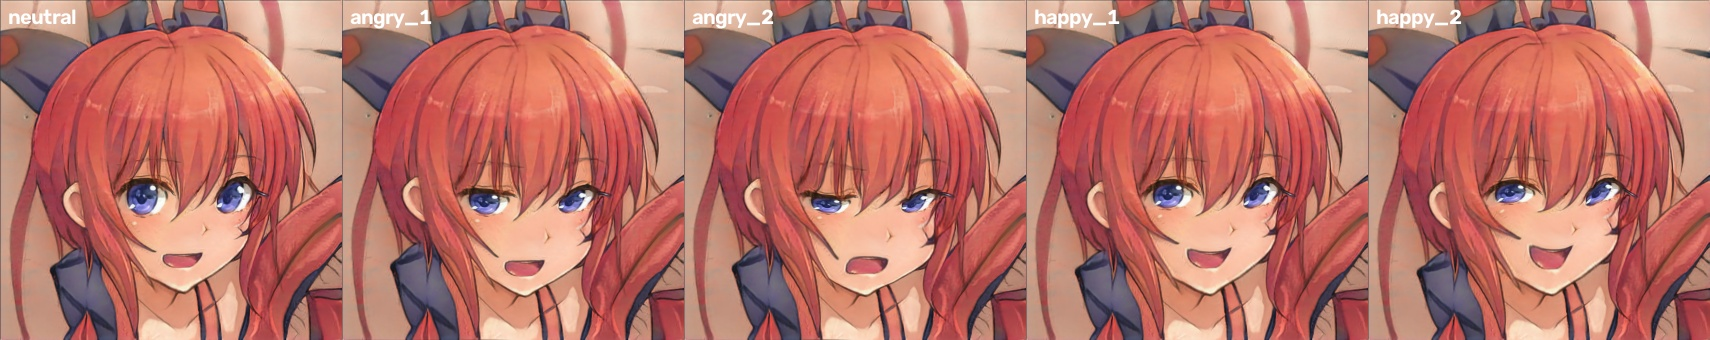

In [ ]:
FINAL = PHASEB / '_phaseB_final'
CKPT = FINAL / 'phaseB_best.pth' if (FINAL / 'phaseB_best.pth').exists() else PHASEB / 'C4_motion_emo_e20_lr3e4' / 'phaseB_best.pth'
OFFP = FINAL / 'label_offsets_train.npz' if (FINAL / 'label_offsets_train.npz').exists() else PHASEB / 'label_offsets_train.npz'
meta = torch.load(str(CKPT), map_location='cpu', weights_only=False)
MOTION_PTS, LEAD = meta.get('motion_pts'), int((meta.get('phaseB_cfg') or {}).get('audio_lead', 8))
assert meta.get('mode') == 'motion', 'Checkpoint khong phai che do motion (C1..C4): %s' % CKPT
model = StudentAudio2Landmark.from_checkpoint(str(CKPT), map_location='cpu').to(DEVICE).eval()
zo = np.load(OFFP)
OFF = {(int(e), int(l)): v.astype(np.float32) for e, l, v in zip(zo['emo'], zo['lvl'], zo['off'])}
ms = np.loadtxt(REPO_DIR / 'src' / 'dataset' / 'utils' / 'MEAN_STD_AUTOVC_RETRAIN_MEL_AU.txt').reshape(2, 80)
MEL_MEAN, MEL_STD = ms[0].astype(np.float32), np.maximum(ms[1], 1e-5).astype(np.float32)

PROFILE_BASE = dict(PROFILE)                         # cau hinh Cell 1 (con 'auto'), de doi nhan vat


def setup_character(name, char_dir=None, verbose=True):
    # nap bo file nhan vat + moi thu phu thuoc nhan vat (dung lai khi doi nhan vat o man hinh demo, Cell 11)
    global CH, CHAR_DIR, CHARACTER, PROFILE, FRAME, CARTOON, EXPR_POSES, DATA_W, BANK, BANK_CARTOON, WARP, BASE_PX, PAINT
    CHAR_DIR = Path(char_dir) if char_dir else next((d for d in CHAR_DIRS if (d / (name + '_face_open_mouth.txt')).exists()), None)
    assert CHAR_DIR is not None, 'Khong thay bo file nhan vat %s trong %s' % (name, CHAR_DIRS)
    CH = A.Character(CHAR_DIR, name); CHARACTER = name
    _sty = {**DEFAULT_STYLE, **CHAR_STYLE.get(name, {})}
    PROFILE = {**PROFILE_BASE, **{k: v for k, v in _sty.items() if PROFILE_BASE.get(k, 'auto') == 'auto'}}
    if verbose:
        print('kieu mat:', PROFILE['eye_style'], '| ve may:', PROFILE['draw_brows'], '| keo may:', PROFILE['brow_gain'],
              '| bien dang:', PROFILE['warper'], '| khau hinh x%.1f' % PROFILE['motion_gain'])
    FRAME = A.MeadFrame(MEAD_REF, CH, PROFILE['scale_ref'])
    src_ = PROFILE.get('expr_source', 'data+cartoon')
    CARTOON = {e: FRAME.from_char(v * PROFILE.get('cartoon_strength', 1.0)).reshape(136)
               for e, v in A.cartoon_expressions(CH).items()} if 'cartoon' in src_ else {}
    EXPR_POSES = CH.load_expr_poses(PROFILE['expr_poses'], FRAME)
    DATA_W = PROFILE.get('data_gain', 1.0) if 'data' in src_ else 0.0
    BANK = A.EmotionBank(OFF, model.emotion_dim, EXPR_POSES, extra=CARTOON, data_weight=DATA_W)
    BANK_CARTOON = A.EmotionBank(OFF, model.emotion_dim, EXPR_POSES, extra=CARTOON, data_weight=0.0)  # khi F2 thay phan du lieu
    WARP = (A.SmoothWarper if PROFILE['warper'] == 'tps' else A.Warper)(CH.img, CH.open_px)
    BASE_PX = CH.to_px(CH.close_norm + PROFILE['mouth_rest'] * (CH.open_norm - CH.close_norm))   # mat nghi (pixel)
    PAINT = A.FacePainter(CH.img, CH.open_px)


setup_character(CHARACTER)

# ---- che do gon: cam xuc nao, 2 muc ----
F2_META = torch.load(str(F2_CKPT), map_location='cpu', weights_only=False) if F2_CKPT.exists() else None
if FOCUS:
    if FOCUS_EMOTIONS == 'auto':
        KEEP_NAMES = tuple(F2_META['keep_names']) if F2_META is not None else ('happy', 'angry')
    else:
        KEEP_NAMES = tuple(FOCUS_EMOTIONS)
    FOCUS_CODES = A.focus_presets(KEEP_NAMES)
    print('CHE DO GON: neutral +', ' + '.join(KEEP_NAMES), '| ma bieu cam:', FOCUS_CODES,
          '| nhan cam xuc:', F2_CKPT.name if F2_META is not None else 'CHUA CO F2 (chay notebook phaseF Cell 9-11)')
else:
    KEEP_NAMES, FOCUS_CODES = tuple(A.EMO_NAMES[1:]), None
# PCA chuyen dong mieng-ham tu MEAD that (12 speaker train), luu cache tren Drive
PCA_PATH = PHASEB / 'mouth_pca.npz'
MOUTH_PCA = None
try:
    if PCA_PATH.exists():
        MOUTH_PCA = dict(np.load(PCA_PATH))
    else:
        t0 = time.time()
        MOUTH_PCA = A.fit_mouth_pca([READY / (s + '.npz') for s in split['train'][:12]], MOTION_PTS, k=12)
        np.savez(PCA_PATH, **MOUTH_PCA)
        print('Hoc PCA mieng-ham: %.0f s -> %s' % (time.time() - t0, PCA_PATH))
    print('PCA mieng-ham: %d thanh phan giai thich %.1f%% bien thien' % (len(MOUTH_PCA['sigma']), 100 * MOUTH_PCA['evr'].sum()))
except Exception as e:
    print('Khong hoc duoc PCA mieng (bo qua lop nay):', repr(e)[:150])
print('checkpoint:', CKPT.parent.name, '| nhan vat:', CHAR_DIR / CHARACTER)

# A.PRESETS[':v'] = dict(emotion=('happy', 2), eyes='wink', mouth='grin', overlays=['blush'])   # vi du them emoticon


def still(spec, profile=None):
    # 1 khung hinh tinh cua bieu cam (khong khau hinh, khong chop mat)
    profile = profile or PROFILE
    q = A.ExpressionTrack([(0.0, spec)], BANK, CH, blink=False, overlays=profile.get('overlays', True)).sample(1, OUT_FPS)
    P = A.char_landmarks_track(CH, FRAME, q, np.zeros((1, 136), np.float32), profile)
    mc = profile.get('mouth_ctrl') or {}
    if mc.get('limit', True):
        P = A.limit_mouth(P, BASE_PX, open_ratio=mc.get('open_ratio', 0.42), jaw_drop=mc.get('jaw_drop', 0.22),
                          max_width=mc.get('max_width'), jaw_side=mc.get('jaw_side'))
    P = A.smooth_contour(P, CH.open_px)
    q['t'][:] = 0.3
    return PAINT(WARP(P[0]), P[0], q, 0, profile)


if FOCUS:                                           # 5 o: neutral + 2 cam xuc x 2 muc
    p1 = OUT_DIR / ('%s_preview_focus.jpg' % CHARACTER)
    cv2.imwrite(str(p1), A.grid([[still(e)] for e in FOCUS_CODES], FOCUS_CODES, cols=len(FOCUS_CODES), scale=0.5)[0])
    show(p1, 1000)
else:
    p1 = OUT_DIR / ('%s_preview_8emo.jpg' % CHARACTER)
    cv2.imwrite(str(p1), A.grid([[still(e)] for e in A.EMO_NAMES], A.EMO_NAMES, cols=4, scale=0.5)[0])
    EMOTICON_DEMO = [':)', ':d', ':))', ';)', ':p', ":')", ':~', ':o', '8-)', '/-showlove', ':-*', '8*)',
                     '>-|', ':wipe', '|-)', ';-a']
    p2 = OUT_DIR / ('%s_preview_emoticon.jpg' % CHARACTER)
    cv2.imwrite(str(p2), A.grid([[still(e)] for e in EMOTICON_DEMO], EMOTICON_DEMO, cols=4, scale=0.5)[0])
    show(p1); show(p2)

## Cell 5 - Nap audio, tu nhan cam xuc tu giong noi

Cat audio thanh cua so 2.5 s (truot 0.5 s) -> mo hinh SER cho xac suat 8 cam xuc -> lam muot, bo doan im lang ->
**Viterbi** (moi lan doi cam xuc bi phat `switch_penalty`) -> gop doan ngan hon `min_dur` -> moi doan thanh 1 moc
`TIMELINE` (muc 1..3 tu do chac chan, hoac tu SERNet neu dung 'mead'), chuyen dan 0.4 s giua cac doan.
Ket qua: `AUTO_TL` + bieu do `<audio>_emotion_timeline.png` + bang `<audio>_emotion_segments.json`.
Muon sua vai doan: `SER_EDIT` o Cell 1.

audio: M032_neutral_001 | 5.6 s (0.1 phut)


/usr/local/lib/python3.13/dist-packages/pydub/utils.py:300: SyntaxWarning: invalid escape sequence '\('
  m = re.match('([su]([0-9]{1,2})p?) \(([0-9]{1,2}) bit\)$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:301: SyntaxWarning: invalid escape sequence '\('
  m2 = re.match('([su]([0-9]{1,2})p?)( \(default\))?$', token)
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:310: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(flt)p?( \(default\))?$', token):
/usr/local/lib/python3.13/dist-packages/pydub/utils.py:314: SyntaxWarning: invalid escape sequence '\('
  elif re.match('(dbl)p?( \(default\))?$', token):


funasr version: 1.4.16.


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.0.0.weight, /root/.cache/huggingface/hub/models--emotion2vec--emotion2vec_plus_large/snapshots/6c303ba987b86b93193de93e34bb2b077a6bedc4/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.0.0.bias, /root/.cache/huggingface/hub/models--emotion2vec--emotion2vec_plus_large/snapshots/6c303ba987b86b93193de93e34bb2b077a6bedc4/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.1.0.weight, /root/.cache/huggingface/hub/models--emotion2vec--emotion2vec_plus_large/snapshots/6c303ba987b86b93193de93e34bb2b077a6bedc4/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.1.0.bias, /root/.cache/huggingface/hub/models--emotion2vec--emotion2vec_plus_large/snapshots/6c303ba987b86b93193de93e34bb2b077a6bedc4/model.pt
Warning, miss key in ckpt: modality_encoders.AUDIO.decoder.blocks.2.0.weight, /root/.cache/huggingface/hub/models--emotion2vec--emotion2vec_plus_large/snapshots

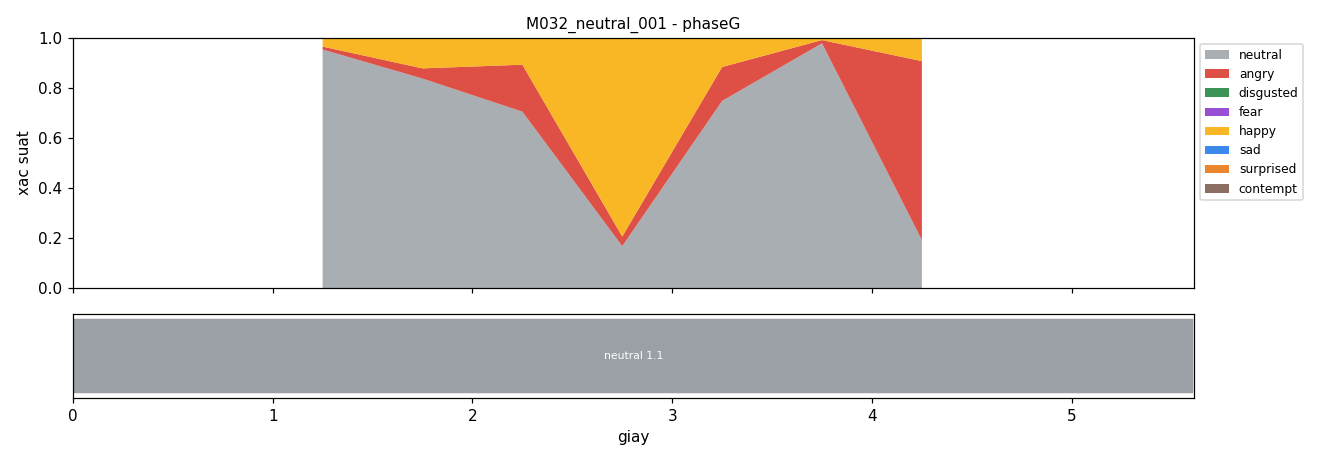

In [ ]:
def get_audio(path):
    if path == 'upload':
        path = upload_one()
    if path:
        return A.load_wav_16k(path), Path(path).stem
    tf = tarfile.open(MEAD_SRC / 'M032' / 'audio.tar')               # cau mau: speaker test, chua tung train
    m = 'audio/neutral/level_1/001.m4a'
    tf.extract(m, '/tmp/demo_audio', filter='data')
    return A.load_wav_16k('/tmp/demo_audio/' + m), 'M032_neutral_001'


Y, AUDIO_NAME = get_audio(AUDIO_PATH)
DUR = len(Y) / 16000
print('audio: %s | %.1f s (%.1f phut)' % (AUDIO_NAME, DUR, DUR / 60))
def get_e2vf():
    global E2VF
    if 'E2VF' not in globals():
        if E2V_TEST:
            E2VF = __import__('fake_e2v').FakeE2V()
        else:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'funasr', 'modelscope'], check=False)
            E2VF = EA.E2VFeat(size=F2_META['e2v_size'], device=DEVICE.type)
    return E2VF


_BR_CACHE = {}


def get_branch(use):
    if use not in _BR_CACHE:
        _BR_CACHE[use] = EA.load_emo_branch(F2_PATHS[use], DEVICE)
    return _BR_CACHE[use]


def analyze_emotion(y, name, use=None, neutral_weight=None, edits=None, plot=True, verbose=True):
    # NHAN CAM XUC TU AUDIO -> dict(tl, segs, f2, centers, prob, png, use, share). Dung o Cell 5 va man hinh demo (Cell 11).
    global E2V
    t0 = time.time(); dur = len(y) / 16000
    use = use or SER_MODEL
    ens = use.endswith('+e2v')                                   # gop xac suat F2 + lop phan loai goc cua emotion2vec+
    use = use.replace('+e2v', '')
    if use == 'phaseG' and not F2_PATHS['phaseG'].exists():
        use = 'phaseF2'
    if use == 'phaseF2' and not F2_PATHS['phaseF2'].exists():
        print('Chua co %s -> dung emotion2vec (chi nhan). Chay notebook phaseF Cell 9-11.' % F2_PATHS['phaseF2']); use = 'emotion2vec'
    if use in ('mead', 'both') and not SER_CKPT.exists():
        print('Chua co SERNet (%s) -> dung emotion2vec.' % SER_CKPT); use = 'emotion2vec'
    runs, f2 = [], None
    if use in F2_PATHS:
        BR, F2M_ = get_branch(use)
        c, EMB = EA.window_embeddings_audio(get_e2vf(), y, SER_CFG['win'], SER_CFG['hop'])   # emotion2vec+ RIENG tung cua so
        mask = torch.full((8,), float('-inf'), device=DEVICE); mask[F2M_['keep']] = 0.0
        with torch.no_grad():
            Sx, Lg, Lv = BR(torch.tensor(EMB).to(DEVICE)); Lg = Lg + mask
            P_ = torch.softmax(Lg / SER_CFG.get('f2_temp', 1.0), -1).cpu().numpy(); COND = BR.cond_vector(Lg, Lv).cpu().numpy()
        head = F2M_.get('e2v_head') or getattr(get_e2vf(), 'head', None)
        if ens and head is not None:                             # cung vector cua so -> khong ton them emotion2vec+
            Ph = EA.head_probs(head, EMB) * np.isin(np.arange(8), F2M_['keep'])
            Ph = Ph / np.maximum(Ph.sum(1, keepdims=True), 1e-8)
            w = float(SER_CFG.get('ens_w', 0.5))
            P_ = (1 - w) * P_ + w * Ph
        elif ens:
            print('Khong co lop phan loai emotion2vec+ -> chi dung F2')
        STATIC = Sx.cpu().numpy() * F2M_['zero_lmd']                  # bieu cam tinh (khong gian MEAD) moi cua so
        quiet = S.window_energy(y, c, SER_CFG['win']) < SER_CFG.get('silence_db', -35.0)
        STATIC[quiet] = 0.0; COND[quiet] = 0.0                           # doan im lang -> mat nghi
        f2 = dict(centers=c, static=STATIC, cond=COND)
        runs.append((c, P_, Lv.cpu().numpy()))
    if use in ('emotion2vec', 'both'):
        if 'E2V' not in globals():
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'funasr', 'modelscope'], check=False)
            E2V = S.Emotion2VecSER(size='large', device=DEVICE.type)
        c, P_ = E2V.windows(y, SER_CFG['win'], SER_CFG['hop'])
        runs.append((c, P_, None))
    if use in ('mead', 'both'):
        SERNET, _ = S.load_sernet(SER_CKPT, DEVICE)
        mel = (A.mel_autovc(y) - MEL_MEAN) / MEL_STD
        c, P_, L_ = S.sernet_windows(SERNET, mel, win=int(round(SER_CFG['win'] * 62.5)), hop=int(round(SER_CFG['hop'] * 62.5)),
                                     device=DEVICE)
        runs.append((c, P_, L_))
    centers = runs[0][0]
    prob = np.mean([np.stack([np.interp(centers, c, P_[:, j]) for j in range(8)], 1) for c, P_, _ in runs], 0)
    levels = next((np.interp(centers, c, L_) for c, _, L_ in runs if L_ is not None), None)
    cfg = {k: v for k, v in SER_CFG.items() if k not in ('win', 'hop', 'neutral_weight_f2', 'f2_temp', 'ens_w')}
    if FOCUS:                                                    # chi cac cam xuc duoc giu, khong emoticon
        cfg.update(allowed=('neutral',) + KEEP_NAMES, emoticon=False)
    if use in F2_PATHS:
        cfg['neutral_weight'] = SER_CFG.get('neutral_weight_f2', 1.0)
    if neutral_weight is not None:
        cfg['neutral_weight'] = float(neutral_weight)
    tl, segs = S.probs_to_timeline(centers, prob, S.window_energy(y, centers, SER_CFG['win']), levels, dur, **cfg)
    if FOCUS:                                                    # (cam xuc, muc) -> ma 2 muc
        fc = lambda sp: sp if isinstance(sp, str) else A.focus_code(sp[0], sp[1])
        tl = [(t, fc(sp)) for t, sp in tl]
        for sg in segs:
            sg['spec'] = fc(sg['spec'])
    if edits:
        tl = S.apply_edits(tl, edits)
    share = {}                                                   # % thoi gian moi cam xuc
    for sg in segs:
        share[sg['emo']] = share.get(sg['emo'], 0.0) + (sg['end'] - sg['start']) / max(dur, 1e-6)
    png = None
    if plot:
        png = OUT_DIR / ('%s_emotion_timeline.png' % name)
        S.plot_timeline(centers, prob, segs, png, '%s - %s' % (name, use))
        (OUT_DIR / ('%s_emotion_segments.json' % name)).write_text(json.dumps(
            [{k: (list(v) if isinstance(v, tuple) else v) for k, v in sg.items()} for sg in segs], indent=1, ensure_ascii=False))
    if verbose:
        print('%d doan cam xuc | %.0f s | %s' % (len(segs), time.time() - t0, use))
        for sg in segs:
            print('  %6.1f - %6.1f s  %-10s muc %.1f  (tin cay %.2f)  -> %s' % (sg['start'], sg['end'], sg['emo'], sg['level'],
                                                                                sg['conf'], sg['spec']))
        print('  ty le thoi gian:', {k: '%.0f%%' % (100 * v) for k, v in share.items()},
              '| xac suat TB:', {A.EMO_NAMES[k]: round(float(prob[:, k].mean()), 2) for k in range(8) if prob[:, k].mean() > 0.01})
    return dict(tl=tl, segs=segs, f2=f2, centers=centers, prob=prob, png=png, use=use + ('+e2v' if ens else ''), share=share)


AUTO_TL, SEGS, F2_TRACK = None, None, None
if EMOTION_SOURCE == 'auto':
    EMO_RES = analyze_emotion(Y, AUDIO_NAME, edits=SER_EDIT)
    AUTO_TL, SEGS, F2_TRACK = EMO_RES['tl'], EMO_RES['segs'], EMO_RES['f2']
    if F2_TRACK is not None:
        print('Bieu cam tinh: lay LIEN TUC tu EmoBranch F2 (hoc tu audio), khong dung bang tra theo nhan.')
    show(EMO_RES['png'], 900)
else:
    print('EMOTION_SOURCE = manual -> dung EXPRESSION / TIMELINE')

## Cell 6 - Render video day du

Dung `AUTO_TL` (neu `EMOTION_SOURCE = 'auto'`), nguoc lai `TIMELINE` hoac `EXPRESSION`. Khung hinh duoc ghi thang ra
file qua ffmpeg nen audio 3 phut (~4500 khung) khong ton RAM. Luu `phaseC_demo/<nhan vat>_<ten>.mp4` + landmark `.npy`.

In [ ]:
def spec_name(sp):
    if isinstance(sp, str):
        return sp
    if isinstance(sp, dict) and ({'eyes', 'mouth', 'overlays', 'motion'} & set(sp)):
        return 'custom'
    mm = A.parse_mix(sp.get('emotion') if isinstance(sp, dict) and 'emotion' in sp else sp)
    return 'neutral' if not mm else '+'.join('%s%.1f' % (A.EMO_NAMES[e], l) for e, l in mm.items())


def f2_frames(f2, n, smooth_sec=1.0):
    # bieu cam tinh + dieu kien C4 cua F2 (moi 0.5 s) -> tung khung 62.5 fps, lam muot ~1 s
    t = np.arange(n) / A.FPS_MODEL; k = max(1, int(smooth_sec * A.FPS_MODEL)) | 1
    ker = np.ones(k) / k
    f = lambda a: np.stack([np.convolve(np.pad(np.interp(t, f2['centers'], a[:, j]), (k // 2, k // 2), mode='edge'), ker, 'valid')
                            for j in range(a.shape[1])], 1).astype(np.float32)
    return f(f2['static']), f(f2['cond'])


def render(y, expr=None, timeline=None, profile=None, voice_shift=0, name='demo', fps=OUT_FPS, save=True,
           keep=False, label=SHOW_LABEL, seed=0, verbose=True, f2=None):
    # save: ghi mp4 (tung khung); keep: tra ve list khung (chi dung cho doan ngan, vd video luoi)
    # f2: F2_TRACK (Cell 5) -> bieu cam tinh lien tuc hoc tu audio thay cho bang tra theo nhan
    t0 = time.time()
    profile = profile or PROFILE
    keys = timeline if timeline else [(0.0, expr)]
    mel = (A.mel_autovc(y) - MEL_MEAN) / MEL_STD
    ov = profile.get('overlays', True)
    trk = A.ExpressionTrack(keys, BANK, CH, blink=profile.get('blink', True), seed=seed, overlays=ov)
    qm = trk.sample(len(mel), A.FPS_MODEL)
    if f2 is not None:                                              # phan du lieu = F2; lop hoat hinh (mat, mieng) giu theo doan
        st_, cond_ = f2_frames(f2, len(mel))
        qc = A.ExpressionTrack(keys, BANK_CARTOON, CH, blink=False, overlays=ov).sample(len(mel), A.FPS_MODEL)
        qm['off'] = qc['off'] + float(profile.get('f2_gain', 1.0)) * st_
        qm['vec'] = cond_
    pred = A.predict_motion(model, mel, qm['vec'], lead=LEAD, device=DEVICE)
    _, dyn = A.mead_residual(pred, MOTION_PTS, 0.0)
    mc = profile.get('mouth_ctrl') or {}
    if mc.get('prior', True) and MOUTH_PCA is not None:             # (1) tien nghiem hinh dang mieng
        dyn = A.apply_mouth_prior(dyn, MOUTH_PCA, mc.get('prior_clamp', 2.5), mc.get('keep_residual', 0.25))
    if mc.get('smooth_ms', 110):                                    # (2) lam muot theo thoi gian
        dyn = A.smooth_motion(dyn, win_ms=mc.get('smooth_ms', 110))
    if mc.get('silence_gate', True):                                # (2b) im lang -> mieng nghi
        g = A.silence_gate(y, len(dyn))
        g = np.concatenate([g[LEAD:], np.repeat(g[-1:], LEAD)])[:len(dyn)]   # khung i ung voi audio i + LEAD
        dyn = dyn * g[:, None]
    P = A.char_landmarks_track(CH, FRAME, qm, dyn, profile)
    if mc.get('limit', True):                                       # (3) gioi han tren khuon mat
        P = A.limit_mouth(P, BASE_PX, open_ratio=mc.get('open_ratio', 0.42), jaw_drop=mc.get('jaw_drop', 0.22),
                          max_width=mc.get('max_width'), jaw_side=mc.get('jaw_side'))
    P = A.resample(np.nan_to_num(P, nan=0.0) if np.isnan(P).any() else P, A.FPS_MODEL, fps)
    P = A.smooth_contour(P, CH.open_px)                              # duong ham khong gay goc
    q = trk.sample(len(P), fps)
    ks = sorted(keys, key=lambda k: k[0])
    out, sink, frames = None, None, ([] if keep else None)
    if save:
        safe = ''.join(ch if ch.isalnum() or ch in '_-+.' else '_' for ch in name)
        out = OUT_DIR / ('%s_%s.mp4' % (CHARACTER, safe))
        sink = A.VideoSink(out, fps, (CH.img.shape[1], CH.img.shape[0]), A.pitch_shift(y, voice_shift))
        np.save(OUT_DIR / ('%s_%s_landmarks.npy' % (CHARACTER, safe)), P.astype(np.float32))
    j = 0
    for i, p in enumerate(P):
        f = PAINT(WARP(p), p, q, i, profile)
        if label:
            t_ = i / fps
            while j + 1 < len(ks) and ks[j + 1][0] <= t_:
                j += 1
            jj = j + 1 if j + 1 < len(ks) and t_ > 0.5 * (ks[j][0] + ks[j + 1][0]) else j   # qua nua doan chuyen -> nhan moi
            txt = spec_name(ks[jj][1]); h = f.shape[0]
            cv2.putText(f, txt, (12, h - 16), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 0, 0), 5, cv2.LINE_AA)
            cv2.putText(f, txt, (12, h - 16), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (255, 255, 255), 2, cv2.LINE_AA)
        if sink is not None:
            sink.write(f)
        if keep:
            frames.append(f)
        if verbose and len(P) > 1500 and (i + 1) % 1000 == 0:
            print('   %d/%d khung | %.0f s' % (i + 1, len(P), time.time() - t0))
    if sink is not None:
        sink.close()
    if verbose:
        print('%-34s %5d khung | %.1f s audio | %.0f s xu ly' % (name, len(P), len(y) / 16000, time.time() - t0))
    return frames, out


if EMOTION_SOURCE == 'auto' and AUTO_TL:
    tl, tag = AUTO_TL, 'auto_' + EMO_RES['use']
else:
    tl, tag = TIMELINE, ('timeline' if TIMELINE else spec_name(EXPRESSION))
_, VIDEO = render(Y, EXPRESSION, tl, voice_shift=VOICE_SHIFT, name='%s_%s' % (AUDIO_NAME, tag),
                  f2=F2_TRACK if (EMOTION_SOURCE == 'auto' and AUTO_TL) else None)
print('Da luu:', VIDEO)
show(VIDEO)

M032_neutral_001_auto_phaseG+e2v     141 khung | 5.6 s audio | 24 s xu ly
Da luu: /content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseC_demo/danbooru1_M032_neutral_001_auto_phaseG+e2v.mp4


## Cell 7 - Video luoi: cung 1 cau o cac bieu cam (che do gon: 5 o; day du: 8 cam xuc muc `GRID_LEVEL`)

In [ ]:
GRID_LEVEL = 3.0
Y_DEMO = Y[:int(DEMO_SECONDS * 16000)]
GRID_SPECS = FOCUS_CODES if FOCUS else [None if e == 'neutral' else (e, GRID_LEVEL) for e in A.EMO_NAMES]
GRID_LABELS = FOCUS_CODES if FOCUS else A.EMO_NAMES
seqs = [render(Y_DEMO, sp, name='grid_' + lb, save=False, keep=True, label=False)[0] for sp, lb in zip(GRID_SPECS, GRID_LABELS)]
GRID_OUT = OUT_DIR / ('%s_%s_grid%d.mp4' % (CHARACTER, AUDIO_NAME, len(GRID_LABELS)))
A.write_video(A.grid(seqs, GRID_LABELS, cols=len(GRID_LABELS) if FOCUS else 4, scale=0.5), GRID_OUT, OUT_FPS,
              A.pitch_shift(Y_DEMO, VOICE_SHIFT))
print('Da luu:', GRID_OUT)
show(GRID_OUT, 760)

grid_neutral                         141 khung | 5.6 s audio | 21 s xu ly
grid_angry_1                         141 khung | 5.6 s audio | 18 s xu ly
grid_angry_2                         141 khung | 5.6 s audio | 10 s xu ly
grid_happy_1                         141 khung | 5.6 s audio | 12 s xu ly
grid_happy_2                         141 khung | 5.6 s audio | 12 s xu ly
Da luu: /content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseC_demo/danbooru1_M032_neutral_001_grid5.mp4


## Cell 8 - Minh hoa chuyen cam xuc giua cau (`DEMO_SECONDS` dau)

`DEMO_SEQ` duoc rai deu theo do dai doan audio; giua 2 moc la doan chuyen muot dai `HOLD` phan (con lai giu nguyen).
Muon tu dat moc theo giay thi dung `TIMELINE` o Cell 1 voi `EMOTION_SOURCE = 'manual'`.

In [ ]:
DEMO_SEQ = (FOCUS_CODES + ['neutral']) if FOCUS else ['neutral', ':d', '>-|', ':~', ':o', ';)']
HOLD = 0.6                                         # 60% moi doan giu nguyen, 40% chuyen dan


def spread(seq, dur, hold=HOLD):
    seg = dur / len(seq); keys = []
    for i, s in enumerate(seq):
        a = i * seg + (0 if i == 0 else (1 - hold) * seg)        # bat dau giu
        keys += [(a, s), (min((i + 1) * seg, dur), s)] if i < len(seq) - 1 else [(a, s), (dur + 1, s)]
    return keys


Y_DEMO = Y[:int(DEMO_SECONDS * 16000)]
TL = spread(DEMO_SEQ, len(Y_DEMO) / 16000)
_, TL_OUT = render(Y_DEMO, timeline=TL, voice_shift=VOICE_SHIFT, name='%s_chuyen_cam_xuc' % AUDIO_NAME)
print('Da luu:', TL_OUT)
show(TL_OUT)

M032_neutral_001_chuyen_cam_xuc      141 khung | 5.6 s audio | 13 s xu ly
Da luu: /content/drive/MyDrive/DAT301m/Data_student/student_a2l/phaseC_demo/danbooru1_M032_neutral_001_chuyen_cam_xuc.mp4


## Cell 9 - Video luoi cac emoticon (`DEMO_SECONDS` dau) - chi che do day du (`FOCUS = False`)

In [ ]:
if FOCUS:
    print('Che do gon: khong dung emoticon/sticker -> bo qua Cell 9 (xem Cell 7).')
else:
    EMO_GRID = [':)', ':d', ':))', ';)', ':p', ":')", ':~', ':o', '8-)', '/-showlove', ':-*', '8*)', '>-|', ':wipe', '|-)', ';-a']
    Y_DEMO = Y[:int(DEMO_SECONDS * 16000)]
    seqs = [render(Y_DEMO, s, name='emo_' + s, save=False, keep=True, label=False, verbose=False)[0] for s in EMO_GRID]
    EG_OUT = OUT_DIR / ('%s_%s_emoticon_grid.mp4' % (CHARACTER, AUDIO_NAME))
    A.write_video(A.grid(seqs, EMO_GRID, cols=4, scale=0.5), EG_OUT, OUT_FPS, A.pitch_shift(Y_DEMO, VOICE_SHIFT))
    print('Da luu:', EG_OUT)
    show(EG_OUT, 760)

Che do gon: khong dung emoticon/sticker -> bo qua Cell 9 (xem Cell 7).


## Cell 10 - (Tuy chon) Chot mo hinh vao `_phaseB_final`

In [ ]:
SRC_RUN = PHASEB / 'C4_motion_emo_e20_lr3e4'
FINAL.mkdir(parents=True, exist_ok=True)
for src, dst in ((SRC_RUN / 'phaseB_best.pth', FINAL / 'phaseB_best.pth'),
                 (SRC_RUN / 'phaseB_history.json', FINAL / 'phaseB_history.json'),
                 (PHASEB / 'label_offsets_train.npz', FINAL / 'label_offsets_train.npz'),
                 (PHASEB / 'phaseB_evaluation.json', FINAL / 'phaseB_evaluation.json')):
    if src.exists():
        shutil.copy2(src, dst)
print(sorted(p.name for p in FINAL.iterdir()))

['label_offsets_train.npz', 'phaseB_best.pth', 'phaseB_evaluation.json', 'phaseB_history.json']


## Cell 11 - MAN HINH DEMO (Gradio): dua anh + audio vao, xem nhan cam xuc, tao video

Chay Cell 0 -> 4 truoc (nap mo hinh), roi chay cell nay -> hien man hinh ngay ben duoi + 1 link `*.gradio.live` (mo o tab
khac / dien thoai, song ~72 gio, chi khi notebook con chay).

* **Tab 1 - Nhan cam xuc**: tai audio -> bieu do xac suat theo thoi gian, bang cac doan, ty le moi cam xuc.
  Dung tab nay de **kiem tra phan nhan cam xuc** truoc khi render.
* **Tab 2 - Tao video**: chon nhan vat co san **hoac tai anh moi** (mat nguoi: tu do; mat hoat hinh: **bam 5 diem**
  tren anh theo thu tu: mat trai, mat phai, dau mui, khoe mieng trai, khoe mieng phai), tai audio, bam *Tao video*.
  Cam xuc `auto` = **tu nhan tu audio** (F2). Thanh truot: do nhay cam xuc, do manh bieu cam, do mo mieng.

In [ ]:
pip install --upgrade gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 13.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 4.1 MB/s eta 0:00:00
  Attempting uninstall: gradio-client
    Found existing installation: gradio_client 2.7.1
    Uninstalling gradio_client-2.7.1:
      Successfully uninstalled gradio_client-2.7.1
  Attempting uninstall: gradio
    Found existing installation: gradio 6.29.0
    Uninstalling gradio-6.29.0:
      Successfully uninstalled gradio-6.29.0


In [ ]:
UI_SHARE = True                    # True: them link public *.gradio.live
UI_TEST = os.environ.get('PHASEC_UI_TEST')
try:
    import gradio as gr
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'gradio'], check=False)
    import gradio as gr

KP_KEYS = ['eye_l', 'eye_r', 'nose', 'mouth_l', 'mouth_r']
KP_VI = ['mat TRAI (ben trai anh)', 'mat PHAI', 'dau MUI', 'khoe mieng TRAI', 'khoe mieng PHAI']
KP_COL = [(255, 60, 60), (60, 160, 255), (60, 200, 60), (255, 160, 0), (200, 60, 255)]


def list_chars():
    out = set()
    for d in CHAR_DIRS:
        out |= {p.name[:-len('_face_open_mouth.txt')] for p in Path(d).glob('*_face_open_mouth.txt')}
    return sorted(out)


def char_from_image(img_rgb, pts, name):
    img = cv2.cvtColor(np.asarray(img_rgb, np.uint8), cv2.COLOR_RGB2BGR); f = 1.0
    if max(img.shape[:2]) > 768:
        f = 768 / max(img.shape[:2]); img = cv2.resize(img, None, fx=f, fy=f, interpolation=cv2.INTER_AREA)
    p68 = None
    if len(pts) < 5:                                               # chua bam du 5 diem -> thu tu do (mat nguoi)
        try:
            subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'mediapipe'], check=False)
            p68 = A.detect_landmarks_mediapipe(img)
        except Exception as e:
            print('MediaPipe loi:', repr(e)[:150])
    if p68 is None and len(pts) >= 5:
        kp = {k: (float(x) * f, float(y) * f) for k, (x, y) in zip(KP_KEYS, pts[:5])}
        r = MEAD_REF.reshape(68, 2)
        tpl = r * np.array([1.0, -1.0]) if r[8, 1] < r[27, 1] else r
        p68 = A.fit_landmarks_from_keypoints(tpl, kp)
    if p68 is None:
        raise gr.Error('Khong tu tim thay mat trong anh. Hay bam 5 diem tren anh: ' + ', '.join(KP_VI))
    A.make_character_files(OUT_DIR / 'characters', name, img, p68)
    cv2.imwrite(str(OUT_DIR / 'characters' / ('%s_anno.jpg' % name)), A.draw_annotation(img, p68))
    return OUT_DIR / 'characters'


def mark(img, pts):
    if img is None:
        return None
    m = np.array(img, np.uint8).copy(); r = max(4, int(0.012 * max(m.shape[:2])))
    for i, (x, y) in enumerate(pts):
        cv2.circle(m, (int(x), int(y)), r, KP_COL[i], -1); cv2.putText(m, str(i + 1), (int(x) + r, int(y) - r),
                                                                     cv2.FONT_HERSHEY_SIMPLEX, 0.6, KP_COL[i], 2)
    return m


def hint(pts):
    n = len(pts)
    return ('Da du 5 diem. (Mat nguoi: khong can bam, se tu do.)' if n >= 5 else
            'Mat hoat hinh: bam diem %d/5 = **%s**. (Mat nguoi: bo qua, se tu do.)' % (n + 1, KP_VI[n]))


def ui_upload(img):
    return img, [], hint([])


def ui_click(orig, pts, evt: gr.SelectData):
    pts = list(pts or [])
    if orig is not None and len(pts) < 5:
        pts.append(tuple(evt.index[:2]))
    return mark(orig, pts), pts, hint(pts)


def ui_reset(orig):
    return orig, [], hint([])


def seg_rows(segs):
    return [[sg['start'], sg['end'], sg['emo'], sg['level'], sg['conf'], str(sg['spec'])] for sg in segs]


def summary_md(R):
    sh = ' | '.join('**%s** %.0f%%' % (k, 100 * v) for k, v in sorted(R['share'].items(), key=lambda kv: -kv[1]))
    pm = ' | '.join('%s %.2f' % (A.EMO_NAMES[k], R['prob'][:, k].mean()) for k in range(8) if R['prob'][:, k].mean() > 0.01)
    return 'Mo hinh: `%s` | %d doan\n\nTy le thoi gian: %s\n\nXac suat trung binh: %s' % (R['use'], len(R['segs']), sh, pm)


def ui_analyze(audio, sens):
    if not audio:
        raise gr.Error('Chua co audio.')
    y = A.load_wav_16k(audio)
    R = analyze_emotion(y, 'ui_%d' % int(time.time()), neutral_weight=sens)
    return str(R['png']), seg_rows(R['segs']), summary_md(R)


def ui_render(char_name, orig, pts, audio, mode, sens, expr_g, mouth_g, seconds):
    if not audio:
        raise gr.Error('Chua co audio.')
    if orig is not None:                                           # anh moi -> tao bo file nhan vat
        nm = 'ui_%d' % int(time.time())
        setup_character(nm, char_from_image(orig, list(pts or []), nm), verbose=False)
    else:
        setup_character(char_name, verbose=False)
    y = A.load_wav_16k(audio)
    if seconds and seconds > 0:
        y = y[:int(seconds * 16000)]
    tag = 'ui_%d' % int(time.time())
    if mode == 'auto':
        R = analyze_emotion(y, tag, neutral_weight=sens); tl, f2 = R['tl'], R['f2']
        png, md_ = str(R['png']), summary_md(R)
    else:
        tl, f2, png, md_ = [(0.0, mode)], None, None, 'Cam xuc chon tay: `%s`' % mode
    prof = dict(PROFILE)
    prof['motion_gain'] = float(PROFILE['motion_gain']) * float(mouth_g)
    prof['f2_gain'] = float(PROFILE.get('f2_gain', 1.0)) * float(expr_g)
    prof['expr_gain'] = {k: v * float(expr_g) for k, v in PROFILE['expr_gain'].items()}
    _, out = render(y, timeline=tl, profile=prof, name=tag, f2=f2)
    return str(out), png, md_


MODES = ['auto'] + (FOCUS_CODES if FOCUS else A.EMO_NAMES)
with gr.Blocks(title='Expressive 2D avatar') as UI:
    gr.Markdown('## Expressive 2D Character Animation - anh + audio -> video co cam xuc')
    with gr.Tab('1. Nhan cam xuc tu audio'):
        with gr.Row():
            with gr.Column(scale=1):
                a1 = gr.Audio(type='filepath', label='Audio giong noi (wav / mp3 / m4a)')
                s1 = gr.Slider(0.3, 1.5, value=SER_CFG.get('neutral_weight_f2', 1.0), step=0.05,
                               label='Trong so "neutral": nho hon -> nhan ra cam xuc nhieu hon')
                b1 = gr.Button('Phan tich cam xuc', variant='primary')
                t1 = gr.Markdown()
            with gr.Column(scale=2):
                i1 = gr.Image(label='Xac suat cam xuc theo thoi gian (tren) va cac doan (duoi)')
                d1 = gr.Dataframe(headers=['bat dau (s)', 'ket thuc (s)', 'cam xuc', 'muc', 'tin cay', 'bieu cam'])
    with gr.Tab('2. Tao video'):
        orig_st, pts_st = gr.State(None), gr.State([])
        with gr.Row():
            with gr.Column(scale=1):
                ch_dd = gr.Dropdown(list_chars(), value=CHARACTER, label='Nhan vat co san (dung khi KHONG tai anh)')
                im = gr.Image(type='numpy', label='HOAC tai anh moi')
                hn = gr.Markdown(hint([]))
                rs = gr.Button('Xoa cac diem da bam')
                a2 = gr.Audio(type='filepath', label='Audio giong noi')
                md_dd = gr.Radio(MODES, value='auto', label='Cam xuc (auto = tu nhan tu audio)')
                s2 = gr.Slider(0.3, 1.5, value=SER_CFG.get('neutral_weight_f2', 1.0), step=0.05, label='Trong so "neutral"')
                g1 = gr.Slider(0.0, 2.0, value=1.0, step=0.1, label='Do manh bieu cam')
                g2 = gr.Slider(0.3, 1.5, value=1.0, step=0.05, label='Do mo mieng khi noi')
                sec = gr.Slider(0, 180, value=0, step=5, label='Chi lay N giay dau (0 = ca audio)')
                b2 = gr.Button('Tao video', variant='primary')
            with gr.Column(scale=1):
                v2 = gr.Video(label='Video')
                i2 = gr.Image(label='Cam xuc tu dong')
                t2 = gr.Markdown()
    b1.click(ui_analyze, [a1, s1], [i1, d1, t1])
    im.upload(ui_upload, [im], [orig_st, pts_st, hn])
    im.clear(lambda: (None, [], hint([])), None, [orig_st, pts_st, hn])
    im.select(ui_click, [orig_st, pts_st], [im, pts_st, hn])
    rs.click(ui_reset, [orig_st], [im, pts_st, hn])
    b2.click(ui_render, [ch_dd, orig_st, pts_st, a2, md_dd, s2, g1, g2, sec], [v2, i2, t2])

if not UI_TEST:
    UI.queue().launch(share=UI_SHARE, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0879dec84f209910a8.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Cell 12 - Danh gia tren AUDIO NHIEU CAM XUC (ghep tu MEAD, biet dap an tung giay)

MEAD moi file chi 1 cam xuc -> cell nay **ghep** cac cau cua speaker **test** (mo hinh chua tung nghe) thanh file dai
~40-60 s co nhieu doan cam xuc doi qua lai (vd neutral -> happy -> angry -> neutral -> ...), moi doan 2-3 cau cung cam xuc.
Vi biet dap an tung 0.1 s, ta **cham diem** phan nhan cam xuc tu dong:

| Metric | Y nghia |
| :--- | :--- |
| **Acc theo thoi gian** | % thoi gian timeline du doan dung cam xuc (sau Viterbi, nhu khi render) |
| **UAR** | trung binh recall cua neutral / 2 cam xuc (khong bi lop dai chi phoi) |
| **Acc tho** | dung argmax xac suat tung cua so, chua lam muot |
| **Diem chuyen** | % diem doi cam xuc that duoc phat hien trong +-1 s, sai lech TB (giay) |
| **So doan** | so doan du doan / so doan that (>1: doi cam xuc qua nhieu, <1: bo sot) |

So **F2** (EmoBranch) voi **emotion2vec+** (cach cu), cung bo loc 3 lop va cung Viterbi. File ghep luu o
`phaseC_demo/test_audio/` -> dung luon o man hinh demo (Cell 11) de xem video.

In [15]:
import random, tarfile
from scipy.io import wavfile
MIX_SPEAKERS  = split['test']          # 4 speaker test
MIX_PER_SPK   = 5                      # so file ghep moi speaker
SEG_PER_MIX   = 7                      # so doan cam xuc moi file
CLIPS_PER_SEG = (2, 3)                 # moi doan 2-3 cau lien tiep cung cam xuc (~6-10 s)
MIX_LEVELS    = (2, 3)                 # muc cam xuc dung (MEAD 1..3; them 1 de thu cam xuc nhe)
GAP_SEC       = 0.3                    # khoang lang giua cac cau
EVAL_MODELS   = ([m for m in ('phaseG+e2v', 'phaseG') if F2_PATHS['phaseG'].exists()] or ['phaseF2+e2v', 'phaseF2']) + ['emotion2vec']
RES = 0.1                              # do phan giai cham diem (giay)
TEST_DIR = OUT_DIR / 'test_audio'; TEST_DIR.mkdir(parents=True, exist_ok=True)
CLS = ['neutral'] + list(KEEP_NAMES)


def load_spk_clips(sp):
    # {cam xuc: [audio 16 kHz]} cho speaker sp (chi cac cam xuc dang giu)
    tmp = Path('/tmp/mixsrc') / sp; tmp.mkdir(parents=True, exist_ok=True)
    out = {}
    with tarfile.open(MEAD_SRC / sp / 'audio.tar') as tf:
        mem = [m for m in tf.getmembers() if m.name.endswith('.m4a')]
        for m in mem:
            parts = Path(m.name).parts; emo, lvl = parts[-3], int(parts[-2].replace('level_', ''))
            if emo not in CLS or (emo != 'neutral' and lvl not in MIX_LEVELS):
                continue
            tf.extract(m, tmp, filter='data')
            out.setdefault(emo, []).append(A.load_wav_16k(tmp / m.name))
    return out


def make_mix(clips, rng):
    # -> (audio, nhan theo luoi RES giay, danh sach doan that)
    seq, prev = [], None
    for _ in range(SEG_PER_MIX):                   # cam xuc lien tiep khac nhau, bat dau bang neutral
        e = 'neutral' if prev is None else rng.choice([c for c in CLS if c != prev])
        seq.append(e); prev = e
    gap = np.zeros(int(GAP_SEC * 16000), np.float32)
    ys, segs, t = [], [], 0.0
    for e in seq:
        n = rng.randint(*CLIPS_PER_SEG)
        part = np.concatenate(sum([[c, gap] for c in rng.sample(clips[e], n)], []))
        ys.append(part); segs.append((t, t + len(part) / 16000, e)); t += len(part) / 16000
    y = np.concatenate(ys)
    grid = np.arange(0, len(y) / 16000, RES)
    gt = np.array([CLS.index(next(s[2] for s in segs if s[0] <= g < s[1] + 1e-9)) for g in grid])
    return y, gt, segs


def pred_grid(R, n):
    grid = np.arange(n) * RES
    lab = np.zeros(n, int)
    for sg in R['segs']:
        lab[(grid >= sg['start']) & (grid < sg['end'] + 1e-9)] = CLS.index(sg['emo']) if sg['emo'] in CLS else 0
    raw_p = np.stack([np.interp(grid, R['centers'], R['prob'][:, A.EMO_NAMES.index(c)]) for c in CLS], 1)
    return lab, raw_p.argmax(1)


def changes(lab):
    return np.where(np.diff(lab) != 0)[0] + 1


def plot_mix(path, segs, R_by, dur, title):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    col = {'neutral': '#9aa0a6', 'angry': '#d93025', 'happy': '#f9ab00', 'sad': '#1a73e8', 'surprised': '#e8710a',
           'fear': '#8430ce', 'disgusted': '#188038', 'contempt': '#795548'}
    rows = [('DAP AN', [(s[0], s[1], s[2]) for s in segs])] + [(k, [(s['start'], s['end'], s['emo']) for s in R['segs']])
                                                              for k, R in R_by.items()]
    fig, ax = plt.subplots(len(rows) + 1, 1, figsize=(13, 1.0 + 0.7 * len(rows) + 1.6), sharex=True,
                           gridspec_kw=dict(height_ratios=[2.2] + [1] * len(rows)))
    R0 = next(iter(R_by.values()))
    for c in CLS:
        ax[0].plot(R0['centers'], R0['prob'][:, A.EMO_NAMES.index(c)], color=col[c], label=c, lw=1.8)
    ax[0].set_ylim(0, 1); ax[0].set_ylabel('xac suat\n' + next(iter(R_by))); ax[0].legend(loc='upper right', fontsize=8, ncol=3)
    ax[0].set_title(title, fontsize=10)
    for a, (nm, ss) in zip(ax[1:], rows):
        for s0, s1, e in ss:
            a.barh(0, s1 - s0, left=s0, color=col.get(e, '#ccc'), edgecolor='white')
            if s1 - s0 > 1.5:
                a.text(0.5 * (s0 + s1), 0, e, ha='center', va='center', fontsize=7, color='white')
        a.set_yticks([0]); a.set_yticklabels([nm], fontsize=8)
    ax[-1].set_xlabel('giay'); ax[-1].set_xlim(0, dur)
    fig.tight_layout(); fig.savefig(path, dpi=110); plt.close(fig)


rng = random.Random(0)
STATS = {m: dict(gt=[], pr=[], raw=[], det=[], err=[], nseg=[]) for m in EVAL_MODELS}
t0 = time.time()
for sp in MIX_SPEAKERS:
    clips = load_spk_clips(sp)
    if any(len(clips.get(c, [])) < CLIPS_PER_SEG[1] for c in CLS):
        print('Bo qua', sp, '(thieu cau)'); continue
    for k in range(MIX_PER_SPK):
        y, gt, segs = make_mix(clips, rng)
        name = '%s_MIX%d_%s' % (sp, k + 1, '-'.join(s[2][:3] for s in segs))
        wavfile.write(str(TEST_DIR / (name + '.wav')), 16000, (np.clip(y, -1, 1) * 32767).astype(np.int16))
        R_by = {}
        for mdl in EVAL_MODELS:
            R = analyze_emotion(y, name, use=mdl, plot=False, verbose=False)
            R_by[mdl] = R
            lab, raw = pred_grid(R, len(gt))
            st = STATS[mdl]; st['gt'].append(gt); st['pr'].append(lab); st['raw'].append(raw)
            cg, cp = changes(gt), changes(lab)
            for c in cg:
                d = np.abs(cp - c).min() * RES if len(cp) else 99.0
                st['det'].append(d <= 1.0); st['err'].append(min(d, 5.0))
            st['nseg'].append((len(cp) + 1) / (len(cg) + 1))
        if k == 0:                                     # 1 hinh minh hoa moi speaker
            plot_mix(TEST_DIR / (name + '.png'), segs, R_by, len(y) / 16000, '%s - %.0f s' % (name, len(y) / 16000))
    print('%s xong | %.0f s' % (sp, time.time() - t0))

print('\n%-12s %-9s %-7s %-9s %-24s %-14s %-9s %s' % ('mo hinh', 'Acc', 'UAR', 'Acc tho', 'recall ' + '/'.join(CLS),
                                                      'diem chuyen', 'sai lech', 'so doan'))
EVAL_MIX = dict(classes=CLS, speakers=MIX_SPEAKERS, n_files=len(STATS[EVAL_MODELS[0]]['gt']), levels=MIX_LEVELS, models={})
for mdl, st in STATS.items():
    if not st['gt']:
        continue
    g, p, r = np.concatenate(st['gt']), np.concatenate(st['pr']), np.concatenate(st['raw'])
    rec = [float((p[g == c] == c).mean()) for c in range(len(CLS))]
    conf = [[int(((g == a) & (p == b)).sum()) for b in range(len(CLS))] for a in range(len(CLS))]
    res = dict(acc=float((p == g).mean()), uar=float(np.mean(rec)), acc_raw=float((r == g).mean()), recall=dict(zip(CLS, rec)),
               change_detect=float(np.mean(st['det'])), change_err_s=float(np.mean(st['err'])), seg_ratio=float(np.mean(st['nseg'])),
               confusion=conf)
    EVAL_MIX['models'][mdl] = res
    print('%-12s %-9.3f %-7.3f %-9.3f %-24s %-14s %-9s %.2f' % (mdl, res['acc'], res['uar'], res['acc_raw'],
          '/'.join('%.2f' % x for x in rec), '%.0f%% trong 1 s' % (100 * res['change_detect']), '%.2f s' % res['change_err_s'],
          res['seg_ratio']))
    print('   ma tran nham lan (hang = that, cot = du doan, don vi 0.1 s):', dict(zip(CLS, conf)))
(TEST_DIR / 'eval_multi_emotion.json').write_text(json.dumps(EVAL_MIX, indent=1))
print('\n%d file ghep + hinh minh hoa + eval_multi_emotion.json -> %s' % (EVAL_MIX['n_files'], TEST_DIR))
for p in sorted(TEST_DIR.glob('*_MIX1_*.png'))[:2]:
    show(p, 1000)

KeyboardInterrupt: 